# **MAJOR PROJECT-RETAIL SALES DATA**

**IMPORTED LIBRARIES**

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from scipy import stats

# Time series:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ML:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.options.display.float_format = "{:,.2f}".format

# shows money in Crore (1 Cr = 10,000,000)
cr_axis = FuncFormatter(lambda x, _: f"₹{x/1e7:,.0f} Cr")
print("Libraries loaded successfully ✔")

Libraries loaded successfully ✔


**LOADING DATASET**

In [2]:
df = pd.read_csv('Retail_Sales_Data_Unlox (1).csv')

df

,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,"29,973.06",39,"1,168,949.34",5,"1,110,501.87",Returning,Debit Card,Yes,422,4.40,South,0
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,"46,933.78",2,"93,867.56",15,"79,787.43",Returning,UPI,No,302,4.10,North,0
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,"39,280.28",44,"1,728,332.32",15,"1,469,082.47",Returning,Cash,No,184,3.80,East,0
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,"40,439.03",9,"363,951.27",5,"345,753.71",New,UPI,Yes,493,3.70,South,0
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,"9,193.58",4,"36,774.32",5,"34,935.60",Returning,Credit Card,No,359,3.50,West,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72995,2024-03-12,STR_105,Pune,PRD_449,Electronics,Accessories,Samsung,"48,317.57",1,"48,317.57",15,"41,069.93",Returning,Credit Card,No,367,4.90,West,0
72996,2023-11-11,STR_108,Ahmedabad,PRD_410,Sports,Gym Equipment,Yonex,"6,368.97",29,"184,700.13",0,"184,700.13",Returning,Debit Card,No,139,4.90,West,0
72997,2023-05-24,STR_108,Ahmedabad,PRD_346,Groceries,Snacks,Britannia,"28,912.38",26,"751,721.88",10,"676,549.69",New,UPI,No,309,3.90,West,0
72998,2024-12-09,STR_103,Delhi,PRD_285,Groceries,Snacks,Nestle,"34,522.32",24,"828,535.68",0,"828,535.68",Returning,Debit Card,No,67,3.90,North,0


**TOTAL DATASET STRUCTURE AND SUMMARY**

In [3]:
df.shape
print("Shape (rows, columns):", df.shape)

print("\n--- First 5 rows ---")
display(df.head())

print("\n--- Column data types ---")
print(df.dtypes)

print("\n--- Summary statistics of numeric columns ---")
display(df.describe().T)


Shape (rows, columns): (73000, 19)

--- First 5 rows ---


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,"29,973.06",39,"1,168,949.34",5,"1,110,501.87",Returning,Debit Card,Yes,422,4.40,South,0
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,"46,933.78",2,"93,867.56",15,"79,787.43",Returning,UPI,No,302,4.10,North,0
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,"39,280.28",44,"1,728,332.32",15,"1,469,082.47",Returning,Cash,No,184,3.80,East,0
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,"40,439.03",9,"363,951.27",5,"345,753.71",New,UPI,Yes,493,3.70,South,0
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,"9,193.58",4,"36,774.32",5,"34,935.60",Returning,Credit Card,No,359,3.50,West,0



--- Column data types ---
Date                    object
Store_ID                object
Store_Location          object
Product_ID              object
Product_Category        object
Product_Subcategory     object
Brand                   object
Unit_Price             float64
Units_Sold               int64
Total_Sales            float64
Discount_Percentage      int64
Revenue                float64
Customer_Type           object
Payment_Mode            object
Promotion_Applied       object
Stock_On_Hand            int64
Store_Rating           float64
Region                  object
Holiday_Flag             int64
dtype: object

--- Summary statistics of numeric columns ---


,count,mean,std,min,25%,50%,75%,max
Unit_Price,"73,000.00","25,110.21","14,393.61",100.11,"12,728.85","25,071.80","37,557.34","49,999.85"
Units_Sold,"73,000.00",24.89,14.13,1.00,13.00,25.00,37.00,49.00
Total_Sales,"73,000.00","626,138.24","544,854.84",144.70,"175,985.23","471,357.72","953,986.38","2,447,350.08"
Discount_Percentage,"73,000.00",10.01,7.06,0.00,5.00,10.00,15.00,20.00
Revenue,"73,000.00","563,476.48","493,890.52",123.00,"157,537.66","422,356.45","857,115.59","2,447,350.08"
Stock_On_Hand,"73,000.00",274.62,129.66,50.00,162.00,274.00,387.00,499.00
Store_Rating,"73,000.00",4.25,0.43,3.50,3.90,4.20,4.60,5.00
Holiday_Flag,"73,000.00",0.01,0.11,0.00,0.00,0.00,0.00,1.00


In [4]:
text_columns = ["Store_ID", "Store_Location", "Region", "Product_Category",
                "Product_Subcategory", "Brand", "Customer_Type", "Payment_Mode", "Promotion_Applied"]

# Convert Date column to datetime if not done,
if not pd.api.types.is_datetime64_any_dtype(df["Date"]):
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in text_columns:
  # Droping NaN values before sorting to avoid comparing float (NaN) with str,
  clean_unique_vals = [val for val in df[col].dropna().unique()]
  print(f"{col}  ({df[col].nunique()} unique): {sorted(clean_unique_vals)}\n")

print("Date range:", df["Date"].min(), "→", df["Date"].max())

Store_ID  (8 unique): ['STR_101', 'STR_102', 'STR_103', 'STR_104', 'STR_105', 'STR_106', 'STR_107', 'STR_108']

Store_Location  (8 unique): ['Ahmedabad', 'Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai', 'Pune']

Region  (4 unique): ['East', 'North', 'South', 'West']

Product_Category  (5 unique): ['Electronics', 'Fashion', 'Groceries', 'Home Appliances', 'Sports']

Product_Subcategory  (15 unique): ['Accessories', 'Athletics', 'Beverages', 'Cleaning', 'Footwear', 'Gym Equipment', 'Household', 'Kitchen', 'Laptops', 'Lighting', 'Men Clothing', 'Mobiles', 'Outdoor', 'Snacks', 'Women Clothing']

Brand  (20 unique): ['Adidas', 'Amul', 'Apple', 'Britannia', 'Decathlon', 'H&M', 'LG', 'Levis', 'Nestle', 'Nike', 'OnePlus', 'Philips', 'Prestige', 'Puma', 'Reebok', 'Samsung', 'Sony', 'Tata', 'Whirlpool', 'Yonex']

Customer_Type  (2 unique): ['New', 'Returning']

Payment_Mode  (4 unique): ['Cash', 'Credit Card', 'Debit Card', 'UPI']

Promotion_Applied  (2 unique): ['No', 'Yes']



**DETECTING OUTLIERS AND DATA QUALITY**

In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "  None – no missing values found ✔")

dup_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {dup_count}")
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Missing values per column:
  None – no missing values found ✔

Duplicate rows found: 0
Rows after removing duplicates: 73000


In [6]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")      # text = real date
print("Invalid / unreadable dates:", df["Date"].isnull().sum())

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()                              # removes spaces

print("Date column type now:", df["Date"].dtype)
print("Days covered:", df["Date"].nunique(), "(Jan 2023 – Dec 2024 = 731 days)")

Invalid / unreadable dates: 0
Date column type now: datetime64[ns]
Days covered: 731 (Jan 2023 – Dec 2024 = 731 days)


In [7]:
checks = {
    "Total_Sales = Unit_Price × Units_Sold":
        np.isclose(df["Unit_Price"] * df["Units_Sold"], df["Total_Sales"], atol=0.01).all(),
    "Revenue = Total_Sales × (1 − Discount%)":
        np.isclose(df["Total_Sales"] * (1 - df["Discount_Percentage"] / 100), df["Revenue"], atol=0.01).all(),
    "All unit prices are positive":      (df["Unit_Price"] > 0).all(),
    "All units sold are positive":       (df["Units_Sold"] > 0).all(),
    "Discount between 0 and 100":        df["Discount_Percentage"].between(0, 100).all(),
    "Store rating between 1 and 5":      df["Store_Rating"].between(1, 5).all(),
    "Holiday_Flag is only 0 or 1":       df["Holiday_Flag"].isin([0, 1]).all(),
    "Each Store_ID has exactly 1 city":  (df.groupby("Store_ID")["Store_Location"].nunique() == 1).all(),
    "Each city belongs to 1 region":     (df.groupby("Store_Location")["Region"].nunique() == 1).all(),
}
for name, passed in checks.items():
    print(("PASS ✔  " if passed else "FAIL ✘  ") + name)

PASS ✔  Total_Sales = Unit_Price × Units_Sold
PASS ✔  Revenue = Total_Sales × (1 − Discount%)
PASS ✔  All unit prices are positive
PASS ✔  All units sold are positive
PASS ✔  Discount between 0 and 100
PASS ✔  Store rating between 1 and 5
PASS ✔  Holiday_Flag is only 0 or 1
PASS ✔  Each Store_ID has exactly 1 city
PASS ✔  Each city belongs to 1 region


In [8]:
for col in ["Revenue", "Units_Sold", "Unit_Price"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:<11} normal range: {low:>14,.0f} to {high:>14,.0f}  → outliers: {n_out:,} ({n_out/len(df):.2%})")

print("\nUnit price range per category (data-quality observation):")
display(df.groupby("Product_Category")["Unit_Price"].agg(["min", "mean", "max"]))

Revenue     normal range:       -891,829 to      1,906,482  → outliers: 937 (1.28%)
Units_Sold  normal range:            -23 to             73  → outliers: 0 (0.00%)
Unit_Price  normal range:        -24,514 to         74,800  → outliers: 0 (0.00%)

Unit price range per category (data-quality observation):


,min,mean,max
Product_Category,,,
Electronics,106.81,"25,056.91","49,998.38"
Fashion,100.11,"25,201.96","49,996.50"
Groceries,104.87,"25,135.24","49,993.58"
Home Appliances,102.05,"25,158.94","49,998.58"
Sports,101.63,"24,999.46","49,999.85"


In [9]:
df["Year"]           = df["Date"].dt.year
df["Quarter"]        = df["Date"].dt.quarter
df["Month"]          = df["Date"].dt.month
df["Month_Name"]     = df["Date"].dt.strftime("%b")
df["Month_Start"]    = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Day_Name"]       = df["Date"].dt.day_name()
df["Day_Of_Week"]    = df["Date"].dt.dayofweek            # Monday = 0
df["Is_Weekend"]     = (df["Day_Of_Week"] >= 5).astype(int)
df["Discount_Amount"] = df["Total_Sales"] - df["Revenue"]   # money given as discount
df["Price_Band"]     = pd.cut(df["Unit_Price"], bins=[0, 10000, 20000, 30000, 40000, 50000],
                              labels=["0-10K", "10-20K", "20-30K", "30-40K", "40-50K"])

print("Cleaning complete and Final shape:", df.shape)
display(df.head(3))

Cleaning complete and Final shape: (73000, 29)


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag,Year,Quarter,Month,Month_Name,Month_Start,Day_Name,Day_Of_Week,Is_Weekend,Discount_Amount,Price_Band
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,"29,973.06",39,"1,168,949.34",5,"1,110,501.87",Returning,Debit Card,Yes,422,4.40,South,0,2023,2,4,Apr,2023-04-01,Thursday,3,0,"58,447.47",20-30K
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,"46,933.78",2,"93,867.56",15,"79,787.43",Returning,UPI,No,302,4.10,North,0,2024,4,10,Oct,2024-10-01,Friday,4,0,"14,080.13",40-50K
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,"39,280.28",44,"1,728,332.32",15,"1,469,082.47",Returning,Cash,No,184,3.80,East,0,2023,1,2,Feb,2023-02-01,Tuesday,1,0,"259,249.85",30-40K


**CALCULATING OVERALL BUSINESS KPI'S**

In [10]:
total_revenue   = df["Revenue"].sum()
total_sales     = df["Total_Sales"].sum()
total_discount  = df["Discount_Amount"].sum()
total_units     = df["Units_Sold"].sum()
transactions    = len(df)

rev_2023 = df.loc[df.Year == 2023, "Revenue"].sum()
rev_2024 = df.loc[df.Year == 2024, "Revenue"].sum()

kpis = {
    "Total Revenue (₹ Cr)":               f"{total_revenue / 1e7:,.2f}",
    "Gross Sales before discount (₹ Cr)": f"{total_sales / 1e7:,.2f}",
    "Discount given (₹ Cr)":              f"{total_discount / 1e7:,.2f}",
    "Units sold":                         f"{total_units:,}",
    "Transactions":                       f"{transactions:,}",
    "Avg revenue per transaction (₹)":    f"{total_revenue / transactions:,.0f}",
    "Avg discount %":                     f"{df['Discount_Percentage'].mean():.2f}",
    "Avg store rating":                   f"{df['Store_Rating'].mean():.2f}",
    "Returning customers %":              f"{(df['Customer_Type'] == 'Returning').mean() * 100:.2f}",
    "Revenue 2023 (₹ Cr)":                f"{rev_2023 / 1e7:,.2f}",
    "Revenue 2024 (₹ Cr)":                f"{rev_2024 / 1e7:,.2f}",
    "YoY growth 2024 vs 2023 %":          f"{(rev_2024 / rev_2023 - 1) * 100:+.2f}",
}
display(pd.Series(kpis, name="Value").to_frame())

,Value
Total Revenue (₹ Cr),"4,113.38"
Gross Sales before discount (₹ Cr),"4,570.81"
Discount given (₹ Cr),457.43
Units sold,"1,817,305"
Transactions,"73,000"
Avg revenue per transaction (₹),"563,476"
Avg discount %,10.01
Avg store rating,4.25
Returning customers %,59.98
Revenue 2023 (₹ Cr),"2,064.11"


**STORE LEVEL PERFORMANCE**

,Rank,Store_ID,Store_Location,Region,Revenue_Cr,Share_%,Transactions,Avg_Transaction,Avg_Rating,YoY_Growth_%
0,1,STR_103,Delhi,North,522.31,12.70,9173,"569,395.43",4.25,-2.34
1,2,STR_102,Bangalore,South,518.63,12.61,9174,"565,323.37",4.25,3.66
2,3,STR_101,Mumbai,West,516.97,12.57,9039,"571,930.00",4.25,-2.12
3,4,STR_104,Chennai,South,516.59,12.56,9186,"562,370.72",4.25,-2.11
4,5,STR_105,Pune,West,516.19,12.55,9254,"557,801.89",4.25,-1.77
5,6,STR_107,Kolkata,East,510.78,12.42,9136,"559,088.47",4.25,0.88
6,7,STR_108,Ahmedabad,West,507.83,12.35,9024,"562,757.31",4.25,-0.25
7,8,STR_106,Hyderabad,South,504.08,12.25,9014,"559,216.36",4.25,-1.54


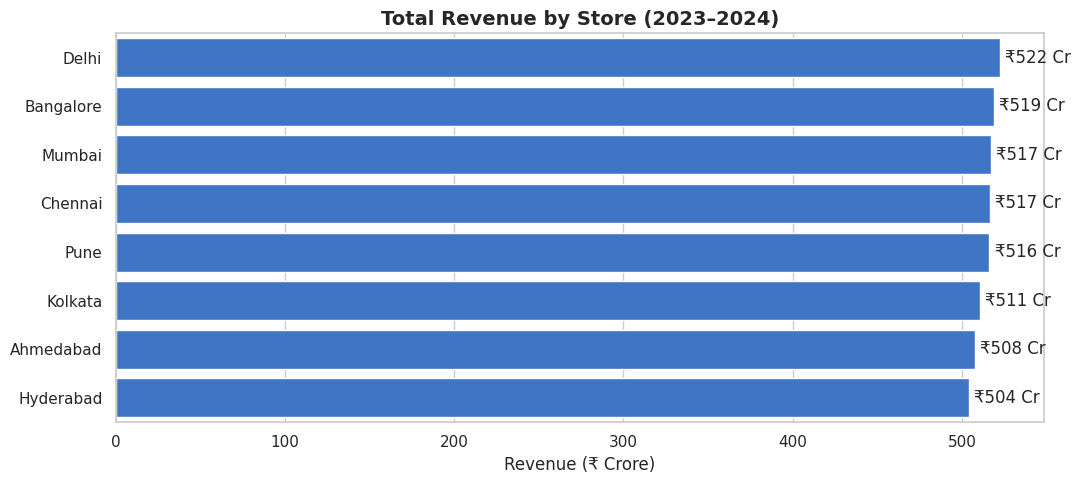

In [11]:
store = (df.groupby(["Store_ID", "Store_Location", "Region"])
           .agg(Revenue=("Revenue", "sum"),
                Transactions=("Revenue", "size"),
                Units=("Units_Sold", "sum"),
                Avg_Transaction=("Revenue", "mean"),
                Avg_Rating=("Store_Rating", "mean"))
           .reset_index())

by_year = df.pivot_table(index="Store_Location", columns="Year", values="Revenue", aggfunc="sum")
by_year["YoY_Growth_%"] = (by_year[2024] / by_year[2023] - 1) * 100

store = store.merge(by_year["YoY_Growth_%"], left_on="Store_Location", right_index=True)
store["Revenue_Cr"] = store["Revenue"] / 1e7
store["Share_%"]    = store["Revenue"] / store["Revenue"].sum() * 100
store = store.sort_values("Revenue", ascending=False).reset_index(drop=True)
store["Rank"] = store.index + 1
display(store[["Rank", "Store_ID", "Store_Location", "Region", "Revenue_Cr", "Share_%",
               "Transactions", "Avg_Transaction", "Avg_Rating", "YoY_Growth_%"]])

fig, ax = plt.subplots()
sns.barplot(data=store, x="Revenue_Cr", y="Store_Location", color="#2a6fdb", ax=ax)
for i, v in enumerate(store["Revenue_Cr"]):
    ax.text(v + 3, i, f"₹{v:,.0f} Cr", va="center")
ax.set_title("Total Revenue by Store (2023–2024)")
ax.set_xlabel("Revenue (₹ Crore)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**REGIONAL PERFORMANCE**

,Region,Revenue,Stores,Transactions,Revenue_Cr,Share_%,Revenue_per_Store_Cr
3,West,"15,409,895,918.25",3,27317,"1,540.99",37.46,513.66
2,South,"15,392,990,381.00",3,27374,"1,539.30",37.42,513.10
1,North,"5,223,064,263.80",1,9173,522.31,12.70,522.31
0,East,"5,107,832,301.69",1,9136,510.78,12.42,510.78


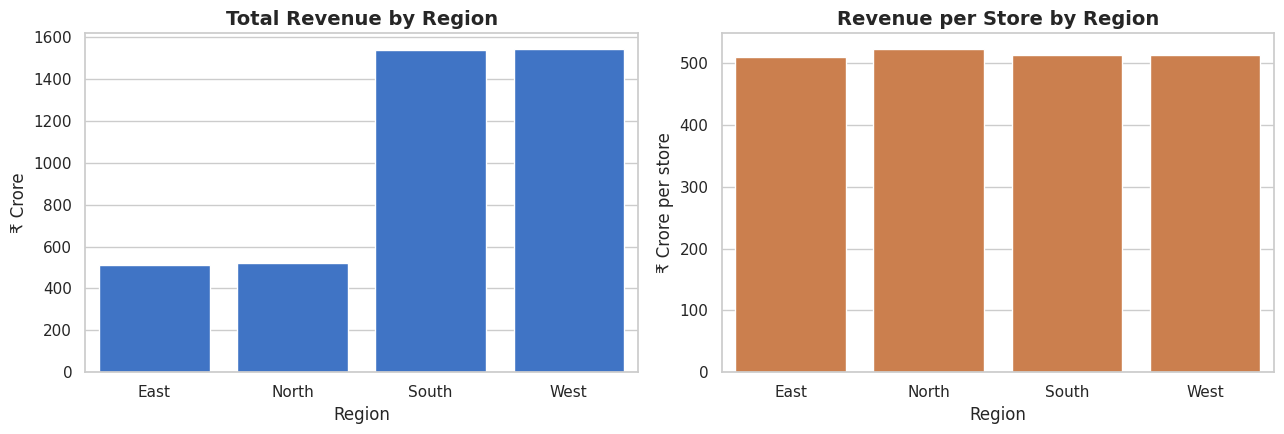

In [12]:
region = (df.groupby("Region")
            .agg(Revenue=("Revenue", "sum"), Stores=("Store_ID", "nunique"), Transactions=("Revenue", "size"))
            .reset_index())
region["Revenue_Cr"]       = region["Revenue"] / 1e7
region["Share_%"]          = region["Revenue"] / region["Revenue"].sum() * 100
region["Revenue_per_Store_Cr"] = region["Revenue_Cr"] / region["Stores"]
display(region.sort_values("Revenue", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=region, x="Region", y="Revenue_Cr", color="#2a6fdb", ax=axes[0])
axes[0].set_title("Total Revenue by Region"); axes[0].set_ylabel("₹ Crore")
sns.barplot(data=region, x="Region", y="Revenue_per_Store_Cr", color="#e07b39", ax=axes[1])
axes[1].set_title("Revenue per Store by Region"); axes[1].set_ylabel("₹ Crore per store")
plt.tight_layout(); plt.show()

**PRODUCT CATEGORY AND SUBCATEGORY PERFORMANCE**

,Product_Category,Revenue,Units,Transactions,Avg_Discount,Revenue_Cr,Share_%
0,Electronics,"8,318,538,868.82",367921,14640,9.95,831.85,20.22
3,Home Appliances,"8,262,751,183.96",365113,14651,10.00,826.28,20.09
1,Fashion,"8,215,645,302.62",361431,14533,9.99,821.56,19.97
2,Groceries,"8,170,528,429.86",359711,14465,10.11,817.05,19.86
4,Sports,"8,166,319,079.48",363129,14711,10.00,816.63,19.85


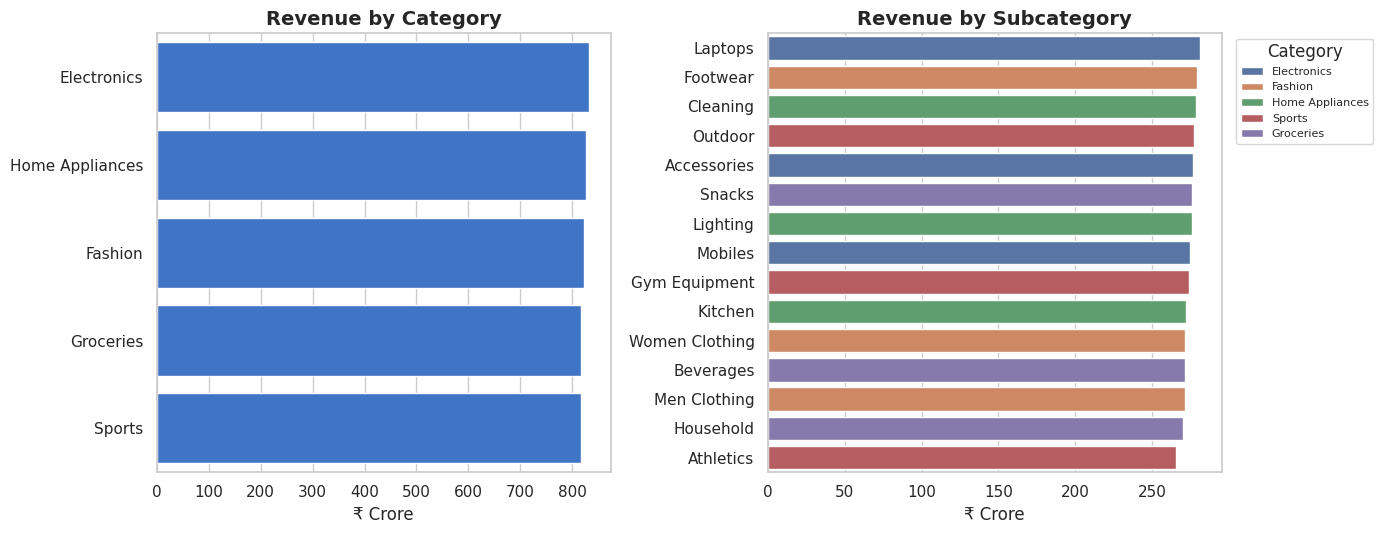

In [13]:
cat = (df.groupby("Product_Category")
         .agg(Revenue=("Revenue", "sum"), Units=("Units_Sold", "sum"), Transactions=("Revenue", "size"),
              Avg_Discount=("Discount_Percentage", "mean"))
         .reset_index())
cat["Revenue_Cr"] = cat["Revenue"] / 1e7
cat["Share_%"]    = cat["Revenue"] / cat["Revenue"].sum() * 100
cat = cat.sort_values("Revenue", ascending=False)
display(cat)

sub = (df.groupby(["Product_Category", "Product_Subcategory"])["Revenue"].sum().div(1e7)
         .reset_index(name="Revenue_Cr").sort_values("Revenue_Cr", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(data=cat, x="Revenue_Cr", y="Product_Category", color="#2a6fdb", ax=axes[0])
axes[0].set_title("Revenue by Category"); axes[0].set_xlabel("₹ Crore"); axes[0].set_ylabel("")
sns.barplot(data=sub, x="Revenue_Cr", y="Product_Subcategory", hue="Product_Category", dodge=False, ax=axes[1])
axes[1].set_title("Revenue by Subcategory"); axes[1].set_xlabel("₹ Crore"); axes[1].set_ylabel("")
axes[1].legend(title="Category", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**REVENUE BY STORE AND PRODUCT CATEGORY**

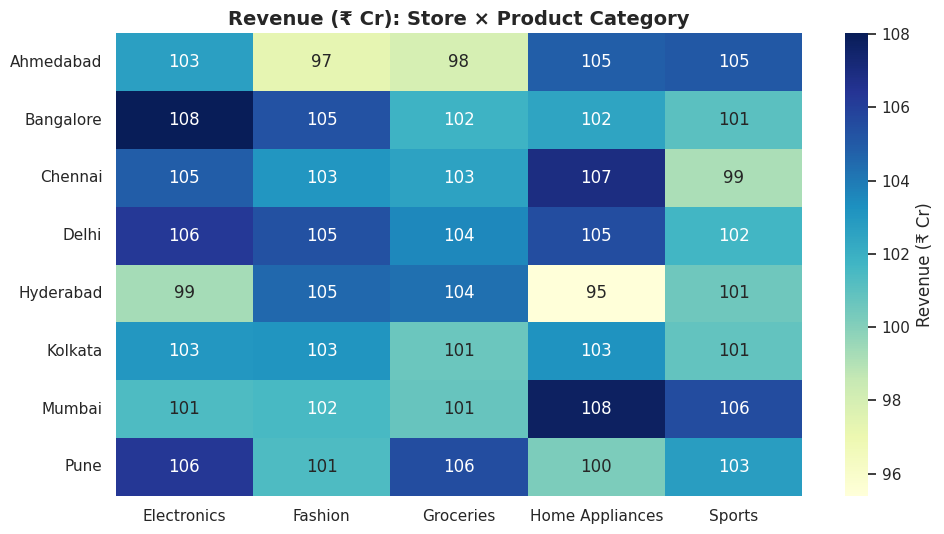

In [14]:
heat = df.pivot_table(index="Store_Location", columns="Product_Category", values="Revenue", aggfunc="sum") / 1e7
plt.figure(figsize=(10, 5.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Revenue (₹ Cr)"})
plt.title("Revenue (₹ Cr): Store × Product Category")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**BRAND LEVEL REVENUE PERFORMANCE**

,Brand,Product_Category,Revenue_Cr
7,Levis,Fashion,213.63
1,Amul,Groceries,210.83
10,OnePlus,Electronics,209.16
15,Samsung,Electronics,208.61
6,LG,Home Appliances,208.46
16,Sony,Electronics,208.17
11,Philips,Home Appliances,208.01
12,Prestige,Home Appliances,206.26
2,Apple,Electronics,205.92
0,Adidas,Sports,205.88


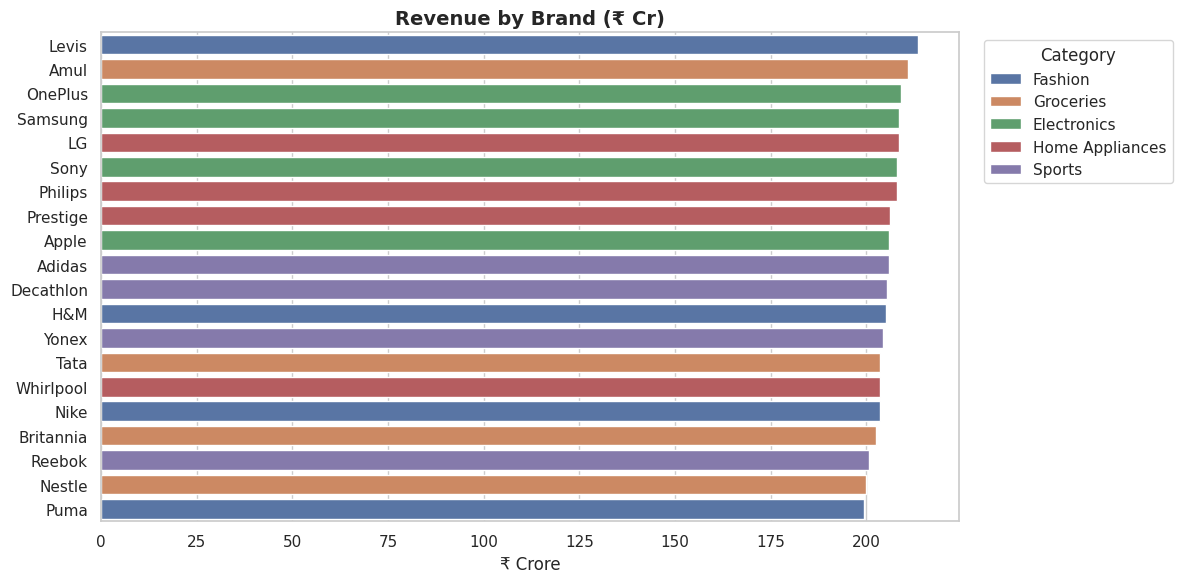

In [15]:
brand = (df.groupby(["Brand", "Product_Category"])["Revenue"].sum().div(1e7)
           .reset_index(name="Revenue_Cr").sort_values("Revenue_Cr", ascending=False))
display(brand.head(10))

plt.figure(figsize=(12, 6))
sns.barplot(data=brand, x="Revenue_Cr", y="Brand", hue="Product_Category", dodge=False)
plt.title("Revenue by Brand (₹ Cr)"); plt.xlabel("₹ Crore"); plt.ylabel("")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**STATISTICAL TESTING USING ONE WAY ANOVA**

In [16]:
def anova_report(column):
    groups = [g["Revenue"].values for _, g in df.groupby(column)]
    f_stat, p_val = stats.f_oneway(*groups)
    verdict = "SIGNIFICANT difference" if p_val < 0.05 else "NO significant difference"
    print(f"{column:<20} F = {f_stat:5.2f}   p-value = {p_val:.4f}   → {verdict}")

print("Does average revenue per transaction differ between groups?\n")
for col in ["Store_ID", "Region", "Product_Category", "Product_Subcategory", "Brand"]:
    anova_report(col)

Does average revenue per transaction differ between groups?

Store_ID             F =  0.97   p-value = 0.4530   → NO significant difference
Region               F =  0.74   p-value = 0.5253   → NO significant difference
Product_Category     F =  1.47   p-value = 0.2080   → NO significant difference
Product_Subcategory  F =  0.98   p-value = 0.4696   → NO significant difference
Brand                F =  1.02   p-value = 0.4281   → NO significant difference


**MONTHLY REVENUE TRENDS**

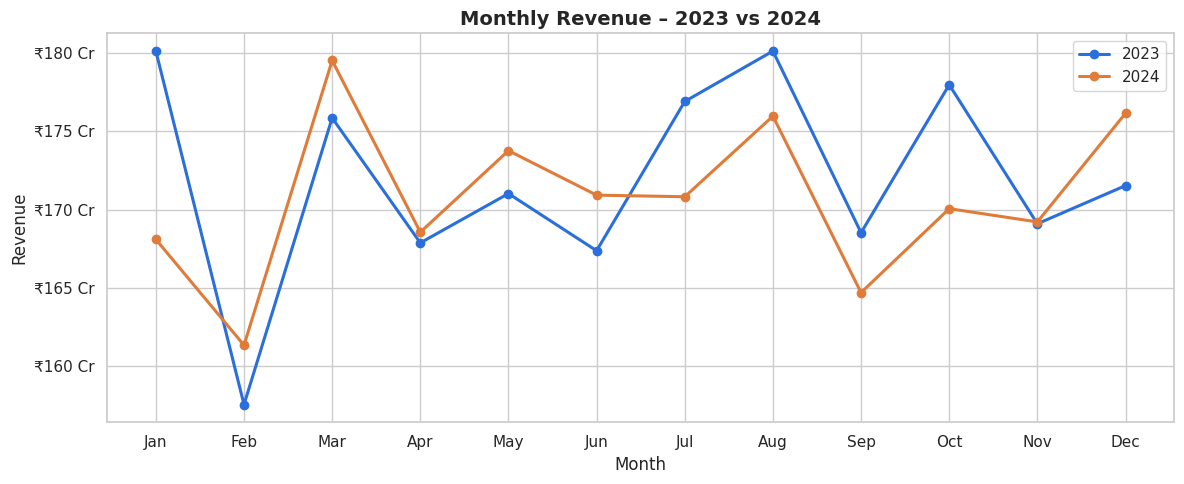

In [17]:
monthly = df.groupby(["Year", "Month"])["Revenue"].sum().reset_index()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 5))
for yr, colr in zip([2023, 2024], ["#2a6fdb", "#e07b39"]):
    d = monthly[monthly.Year == yr]
    plt.plot(d["Month"], d["Revenue"], marker="o", linewidth=2.2, label=str(yr), color=colr)
plt.xticks(range(1, 13), month_labels)
plt.gca().yaxis.set_major_formatter(cr_axis)
plt.title("Monthly Revenue – 2023 vs 2024"); plt.xlabel("Month"); plt.ylabel("Revenue")
plt.legend(); plt.tight_layout(); plt.show()

**ANALYZING MONTHLY AND QUATERLY REVENUE GROWTH**

Monthly revenue in ₹ Cr and year-over-year growth:


Year,2023,2024,YoY_Growth_%
Jan,180.14,168.11,-6.68
Feb,157.56,161.36,2.41
Mar,175.87,179.53,2.08
Apr,167.89,168.57,0.41
May,171.04,173.78,1.60
Jun,167.39,170.94,2.12
Jul,176.92,170.83,-3.44
Aug,180.14,175.98,-2.31
Sep,168.54,164.71,-2.27
Oct,177.99,170.07,-4.45


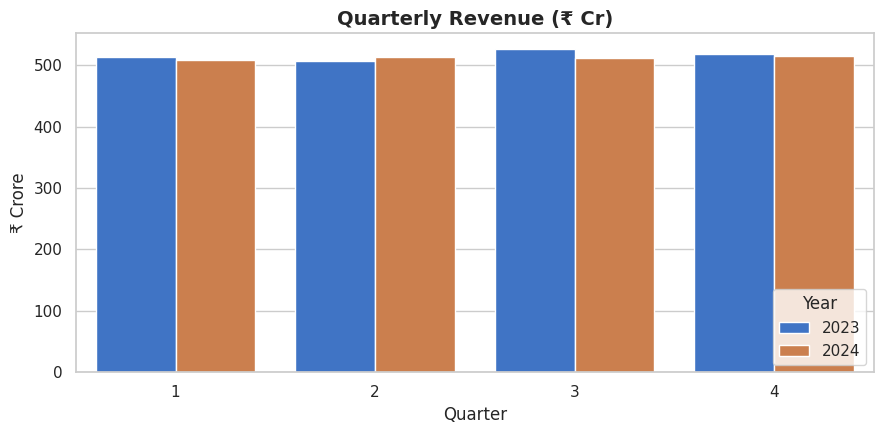

In [18]:
pivot = monthly.pivot(index="Month", columns="Year", values="Revenue")
pivot["YoY_Growth_%"] = (pivot[2024] / pivot[2023] - 1) * 100
pivot.index = month_labels
pivot_cr = pivot.copy(); pivot_cr[[2023, 2024]] = pivot_cr[[2023, 2024]] / 1e7
print("Monthly revenue in ₹ Cr and year-over-year growth:")
display(pivot_cr)

quarter = df.groupby(["Year", "Quarter"])["Revenue"].sum().div(1e7).reset_index(name="Revenue_Cr")
quarter["Year"] = quarter["Year"].astype(str)
plt.figure(figsize=(9, 4.5))
sns.barplot(data=quarter, x="Quarter", y="Revenue_Cr", hue="Year", palette=["#2a6fdb", "#e07b39"])
plt.title("Quarterly Revenue (₹ Cr)"); plt.ylabel("₹ Crore"); plt.xlabel("Quarter")
plt.legend(title="Year", loc="lower right")
plt.tight_layout(); plt.show()

**TESTING SEASONALITY AND MONTHLY EFFECTS**

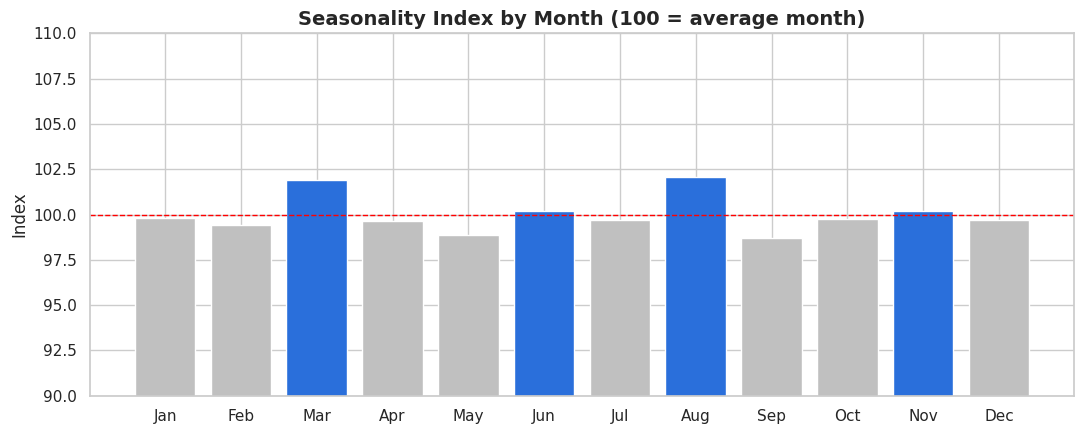

Strongest month: Aug (102.1)   |   Weakest month: Sep (98.7)
Spread between strongest and weakest month: 3.4 index points

Does the 2023 monthly pattern repeat in 2024?  correlation r = -0.36, p-value = 0.25
→ No – the strongest/weakest months change from year to year, so there is NO reliable seasonal pattern.
ANOVA across the 12 months (daily revenue): p-value = 0.96 → no significant difference between months


In [19]:
# Seasonality index by month
# Index 100 = an average month. >100 = stronger than average. We use revenue PER DAY so that
# short months (like February) are not unfairly treated as weak.
m = df.groupby(["Year", "Month"])["Revenue"].sum().reset_index()
m["Days"]      = pd.to_datetime(dict(year=m.Year, month=m.Month, day=1)).dt.days_in_month
m["Per_Day"]   = m["Revenue"] / m["Days"]
m["Index"]     = m["Per_Day"] / m.groupby("Year")["Per_Day"].transform("mean") * 100
seasonal_idx   = m.groupby("Month")["Index"].mean()
seasonal_idx.index = month_labels

colors = ["#2a6fdb" if v >= 100 else "#c0c0c0" for v in seasonal_idx]
plt.figure(figsize=(11, 4.5))
plt.bar(seasonal_idx.index, seasonal_idx.values, color=colors)
plt.axhline(100, color="red", linestyle="--", linewidth=1)
plt.ylim(90, 110)
plt.title("Seasonality Index by Month (100 = average month)"); plt.ylabel("Index")
plt.tight_layout(); plt.show()
print("Strongest month:", seasonal_idx.idxmax(), f"({seasonal_idx.max():.1f})   |   Weakest month:", seasonal_idx.idxmin(), f"({seasonal_idx.min():.1f})")
print(f"Spread between strongest and weakest month: {seasonal_idx.max() - seasonal_idx.min():.1f} index points")

# Is the monthly pattern REAL (does it repeat from one year to the next)?
by_year_idx = m.pivot(index="Month", columns="Year", values="Index")
r, p = stats.pearsonr(by_year_idx[2023], by_year_idx[2024])
print(f"\nDoes the 2023 monthly pattern repeat in 2024?  correlation r = {r:.2f}, p-value = {p:.2f}")
print("→ " + ("Yes, a repeating seasonal pattern exists." if (p < 0.05 and r > 0) else "No – the strongest/weakest months change from year to year, so there is NO reliable seasonal pattern."))

# Do months differ significantly in daily revenue?
daily_rev = df.groupby("Date")["Revenue"].sum().reset_index()
daily_rev["Month"] = daily_rev["Date"].dt.month
f_stat, p_month = stats.f_oneway(*[g["Revenue"].values for _, g in daily_rev.groupby("Month")])
print(f"ANOVA across the 12 months (daily revenue): p-value = {p_month:.2f} →", "significant" if p_month < 0.05 else "no significant difference between months")

**ANALYZING DAY OF WEEK REVENUE PATTERNS**

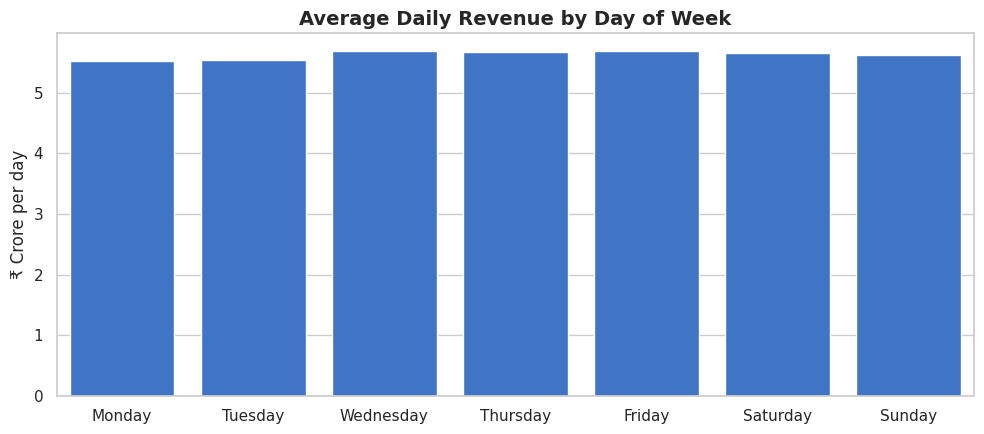

Best day: Friday (₹5.69 Cr)  |  Weakest day: Monday (₹5.52 Cr)
ANOVA across weekdays: p-value = 0.44 → no significant weekday effect (differences are random noise)


In [20]:
daily = df.groupby("Date").agg(Revenue=("Revenue", "sum")).reset_index()
daily["Day_Name"] = daily["Date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = daily.groupby("Day_Name")["Revenue"].mean().reindex(order)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=dow.index, y=dow.values / 1e7, color="#2a6fdb")
plt.title("Average Daily Revenue by Day of Week"); plt.ylabel("₹ Crore per day"); plt.xlabel("")
plt.tight_layout(); plt.show()
print(f"Best day: {dow.idxmax()} (₹{dow.max()/1e7:.2f} Cr)  |  Weakest day: {dow.idxmin()} (₹{dow.min()/1e7:.2f} Cr)")

f_stat, p_dow = stats.f_oneway(*[g["Revenue"].values for _, g in daily.groupby("Day_Name")])
print(f"ANOVA across weekdays: p-value = {p_dow:.2f} →", "significant weekday effect" if p_dow < 0.05 else "no significant weekday effect (differences are random noise)")

**ANALYZING HOLIDAY IMPACT**

In [21]:
print("Months in which Holiday_Flag = 1 occurs:", [int(x) for x in sorted(df.loc[df.Holiday_Flag == 1, "Month"].unique())])
print("Holiday transactions:", int(df.Holiday_Flag.sum()), f"({df.Holiday_Flag.mean():.2%} of all rows)\n")

q4 = df[df["Month"].isin([10, 11, 12])]
holiday = q4.groupby("Holiday_Flag").agg(Transactions=("Revenue", "size"),
                                         Avg_Revenue=("Revenue", "mean"),
                                         Avg_Units=("Units_Sold", "mean"))
holiday.index = ["Normal day (Oct–Dec)", "Holiday (Oct–Dec)"]
display(holiday)

t, p = stats.ttest_ind(q4.loc[q4.Holiday_Flag == 1, "Revenue"], q4.loc[q4.Holiday_Flag == 0, "Revenue"])
print(f"t-test p-value = {p:.4f} →", "holiday effect is SIGNIFICANT" if p < 0.05 else "no significant holiday uplift")

Months in which Holiday_Flag = 1 occurs: [10, 11, 12]
Holiday transactions: 897 (1.23% of all rows)



,Transactions,Avg_Revenue,Avg_Units
Normal day (Oct–Dec),17469,"563,748.42",24.91
Holiday (Oct–Dec),897,"549,462.78",23.85


t-test p-value = 0.3970 → no significant holiday uplift


**DISCOUNT AND PROMOTION EFFECTS**

Effect of discount level:


,Transactions,Avg_Units,Avg_Revenue,Total_Revenue_Cr,Total_Discount_Cr
Discount_Percentage,,,,,
0,14560,24.91,"627,932.46",914.27,0.00
5,14556,24.90,"592,092.50",861.85,45.36
10,14600,24.82,"562,983.99",821.96,91.33
15,14740,25.03,"535,914.84",789.94,139.40
20,14544,24.80,"498,737.41",725.36,181.34



Effect of Promotion_Applied:


,Transactions,Avg_Units,Avg_Revenue,Avg_Discount
Promotion_Applied,,,,
No,51151,24.90,"563,966.66",9.98
Yes,21849,24.88,"562,328.91",10.08


Units sold with vs without promotion: p-value = 0.8657 → no significant volume lift from promotions


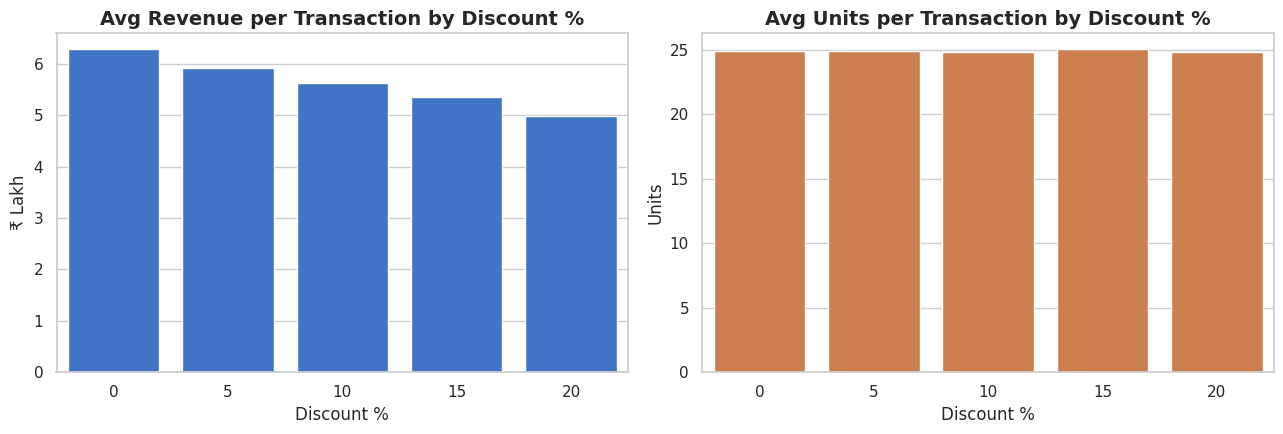

In [22]:
disc = (df.groupby("Discount_Percentage")
          .agg(Transactions=("Revenue", "size"), Avg_Units=("Units_Sold", "mean"),
               Avg_Revenue=("Revenue", "mean"), Total_Revenue=("Revenue", "sum"),
               Total_Discount=("Discount_Amount", "sum")))
disc["Total_Revenue_Cr"]  = disc["Total_Revenue"] / 1e7
disc["Total_Discount_Cr"] = disc["Total_Discount"] / 1e7
print("Effect of discount level:")
display(disc[["Transactions", "Avg_Units", "Avg_Revenue", "Total_Revenue_Cr", "Total_Discount_Cr"]])

promo = df.groupby("Promotion_Applied").agg(Transactions=("Revenue", "size"), Avg_Units=("Units_Sold", "mean"),
                                            Avg_Revenue=("Revenue", "mean"), Avg_Discount=("Discount_Percentage", "mean"))
print("\nEffect of Promotion_Applied:")
display(promo)
t, p = stats.ttest_ind(df.loc[df.Promotion_Applied == "Yes", "Units_Sold"], df.loc[df.Promotion_Applied == "No", "Units_Sold"])
print(f"Units sold with vs without promotion: p-value = {p:.4f} →", "promotion lifts volume" if p < 0.05 else "no significant volume lift from promotions")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=disc.index, y=disc["Avg_Revenue"] / 1e5, color="#2a6fdb", ax=axes[0])
axes[0].set_title("Avg Revenue per Transaction by Discount %"); axes[0].set_ylabel("₹ Lakh"); axes[0].set_xlabel("Discount %")
sns.barplot(x=disc.index, y=disc["Avg_Units"], color="#e07b39", ax=axes[1])
axes[1].set_title("Avg Units per Transaction by Discount %"); axes[1].set_ylabel("Units"); axes[1].set_xlabel("Discount %")
plt.tight_layout(); plt.show()

**ANALYZING CUSTOMER AND PAYMENTS**

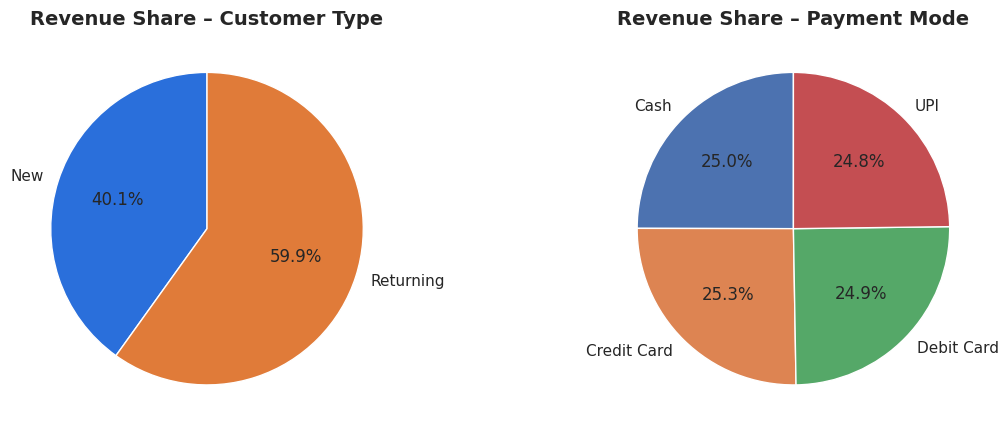

,Transactions,Avg_Revenue,Avg_Units
Customer_Type,,,
New,29218,"564,502.29",24.82
Returning,43782,"562,791.90",24.94


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cust = df.groupby("Customer_Type")["Revenue"].sum()
axes[0].pie(cust, labels=cust.index, autopct="%1.1f%%", startangle=90, colors=["#2a6fdb", "#e07b39"])
axes[0].set_title("Revenue Share – Customer Type")
pay = df.groupby("Payment_Mode")["Revenue"].sum()
axes[1].pie(pay, labels=pay.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Revenue Share – Payment Mode")
plt.tight_layout(); plt.show()

display(df.groupby("Customer_Type").agg(Transactions=("Revenue", "size"), Avg_Revenue=("Revenue", "mean"), Avg_Units=("Units_Sold", "mean")))

**CORRELATION ANALYSIS OF REVENUE DRIVERS**

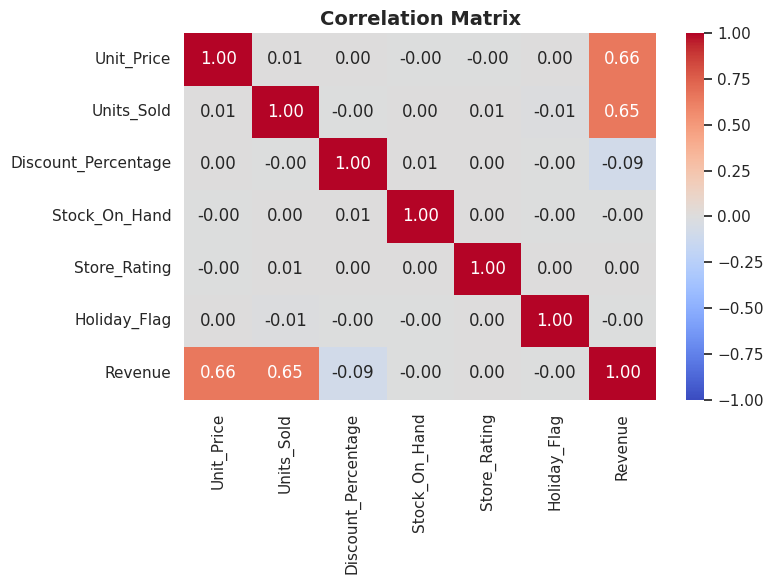

Correlation with Revenue (strongest first):


,Correlation
Unit_Price,0.66
Units_Sold,0.65
Discount_Percentage,-0.09
Holiday_Flag,-0.00
Store_Rating,0.00
Stock_On_Hand,-0.00


In [24]:
driver_cols = ["Unit_Price", "Units_Sold", "Discount_Percentage", "Stock_On_Hand", "Store_Rating", "Holiday_Flag", "Revenue"]
corr = df[driver_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout(); plt.show()

print("Correlation with Revenue (strongest first):")
display(corr["Revenue"].drop("Revenue").sort_values(key=abs, ascending=False).to_frame("Correlation"))

**YEAR BY YEAR CHANGES BY STORE AND CATEGORY**

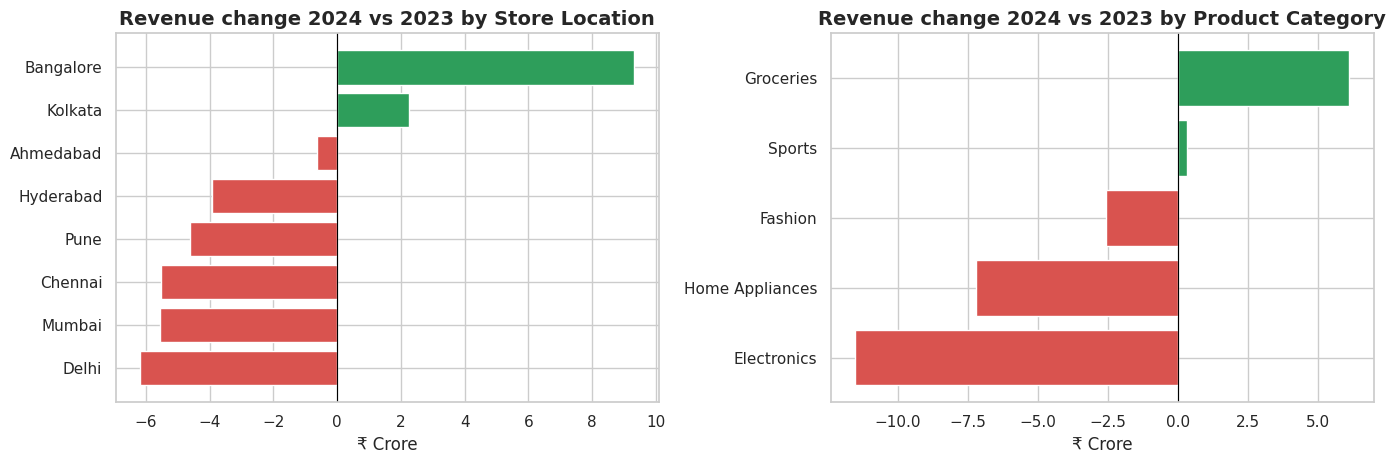

Year,2023,2024,Change_Cr,Growth_%
Store_Location,,,,
Bangalore,"2,546,556,212.04","2,639,720,393.80",9.32,3.66
Kolkata,"2,542,720,160.68","2,565,112,141.01",2.24,0.88
Ahmedabad,"2,542,355,497.53","2,535,966,471.97",-0.64,-0.25
Hyderabad,"2,539,955,184.26","2,500,821,113.18",-3.91,-1.54
Pune,"2,604,022,896.30","2,557,875,785.57",-4.61,-1.77
Chennai,"2,610,537,703.36","2,555,399,774.35",-5.51,-2.11
Mumbai,"2,612,567,134.34","2,557,108,132.54",-5.55,-2.12
Delhi,"2,642,390,719.85","2,580,673,543.95",-6.17,-2.34


Year,2023,2024,Change_Cr,Growth_%
Product_Category,,,,
Groceries,"4,054,586,727.37","4,115,941,702.49",6.14,1.51
Sports,"4,081,488,763.74","4,084,830,315.74",0.33,0.08
Fashion,"4,120,718,105.43","4,094,927,197.20",-2.58,-0.63
Home Appliances,"4,167,402,141.16","4,095,349,042.79",-7.21,-1.73
Electronics,"4,216,909,770.68","4,101,629,098.15",-11.53,-2.73



Revenue by unit-price band:


,Revenue_Cr,Avg_Units
Price_Band,,
0-10K,160.03,24.76
10-20K,493.78,24.88
20-30K,818.05,24.87
30-40K,"1,161.10",25.07
40-50K,"1,480.41",24.90


In [25]:
def change_table(col):
    t = df.pivot_table(index=col, columns="Year", values="Revenue", aggfunc="sum")
    t["Change_Cr"] = (t[2024] - t[2023]) / 1e7
    t["Growth_%"]  = (t[2024] / t[2023] - 1) * 100
    return t.sort_values("Change_Cr")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col in zip(axes, ["Store_Location", "Product_Category"]):
    t = change_table(col)
    ax.barh(t.index, t["Change_Cr"], color=["#d9534f" if v < 0 else "#2e9e5b" for v in t["Change_Cr"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Revenue change 2024 vs 2023 by {col.replace('_', ' ')}"); ax.set_xlabel("₹ Crore")
plt.tight_layout(); plt.show()

display(change_table("Store_Location").sort_values("Change_Cr", ascending=False))
display(change_table("Product_Category").sort_values("Change_Cr", ascending=False))

# Price band: which price segment brings the most revenue?
band = df.groupby("Price_Band", observed=True).agg(Revenue_Cr=("Revenue", lambda x: x.sum() / 1e7), Avg_Units=("Units_Sold", "mean"))
print("\nRevenue by unit-price band:")
display(band)

**REVENUE BY UNIT PRICE BAND**

Months in series: 24 | 2023-01-01 → 2024-12-01

Month-to-month variation: 3.4% on raw monthly totals vs 1.9% after adjusting for month length
→ about 45% of the ups-and-downs in monthly totals is only because months have different numbers of days.

Stationarity & trend checks:
  ADF test   p-value = 0.011  → stationary (p < 0.05)
  KPSS test  p-value = 0.100  → stationary (p > 0.05)
  Linear trend: -0.07% of the average level per month (p = 0.23) → no significant trend


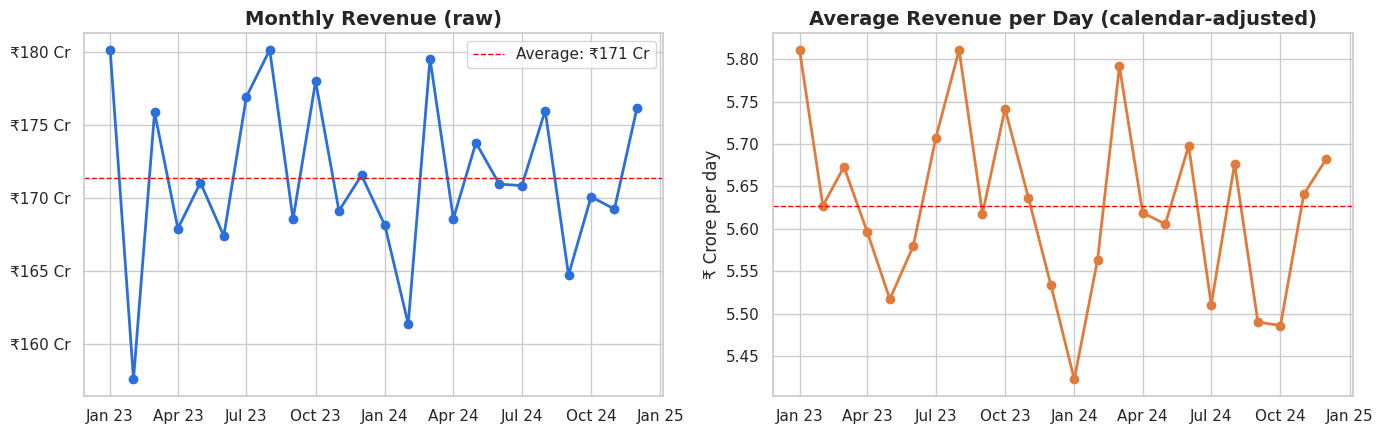

In [26]:
monthly_rev = df.set_index("Date")["Revenue"].resample("MS").sum()      # MS = Month Start
monthly_rev.index.freq = "MS"
days_in_month = pd.Series(monthly_rev.index.days_in_month, index=monthly_rev.index)
daily_avg = monthly_rev / days_in_month                                  # average revenue PER DAY in each month
print("Months in series:", len(monthly_rev), "|", monthly_rev.index.min().date(), "→", monthly_rev.index.max().date())

cv_raw   = monthly_rev.std() / monthly_rev.mean() * 100
cv_daily = daily_avg.std() / daily_avg.mean() * 100
print(f"\nMonth-to-month variation: {cv_raw:.1f}% on raw monthly totals vs {cv_daily:.1f}% after adjusting for month length")
print(f"→ about {(1 - cv_daily / cv_raw):.0%} of the ups-and-downs in monthly totals is only because months have different numbers of days.")

# Is the series stable (stationary)? We use three simple checks. (With only 24 points we limit ADF to 1 lag;
# the automatic setting would use 9 of our 24 points and make the test unreliable.)
adf_stat, adf_p   = adfuller(daily_avg, maxlag=1, autolag=None)[:2]
kpss_stat, kpss_p = kpss(daily_avg, regression="c", nlags="auto")[:2]
trend = stats.linregress(np.arange(len(daily_avg)), daily_avg.values)
slope_pct = trend.slope / daily_avg.mean() * 100

print("\nStationarity & trend checks:")
print(f"  ADF test   p-value = {adf_p:.3f}  → " + ("stationary (p < 0.05)" if adf_p < 0.05 else "not proven stationary"))
print(f"  KPSS test  p-value = {kpss_p:.3f}  → " + ("stationary (p > 0.05)" if kpss_p > 0.05 else "NOT stationary"))
print(f"  Linear trend: {slope_pct:+.2f}% of the average level per month (p = {trend.pvalue:.2f}) → "
      + ("significant trend" if trend.pvalue < 0.05 else "no significant trend"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly_rev.index, monthly_rev.values, marker="o", linewidth=2, color="#2a6fdb")
axes[0].axhline(monthly_rev.mean(), color="red", linestyle="--", linewidth=1, label=f"Average: ₹{monthly_rev.mean()/1e7:,.0f} Cr")
axes[0].yaxis.set_major_formatter(cr_axis); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[0].set_title("Monthly Revenue (raw)"); axes[0].legend()
axes[1].plot(daily_avg.index, daily_avg.values / 1e7, marker="o", linewidth=2, color="#e07b39")
axes[1].axhline(daily_avg.mean() / 1e7, color="red", linestyle="--", linewidth=1)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); axes[1].set_ylabel("₹ Crore per day")
axes[1].set_title("Average Revenue per Day (calendar-adjusted)")
plt.tight_layout(); plt.show()

**TIME SERIES FOR REVENUE FORECASTING**

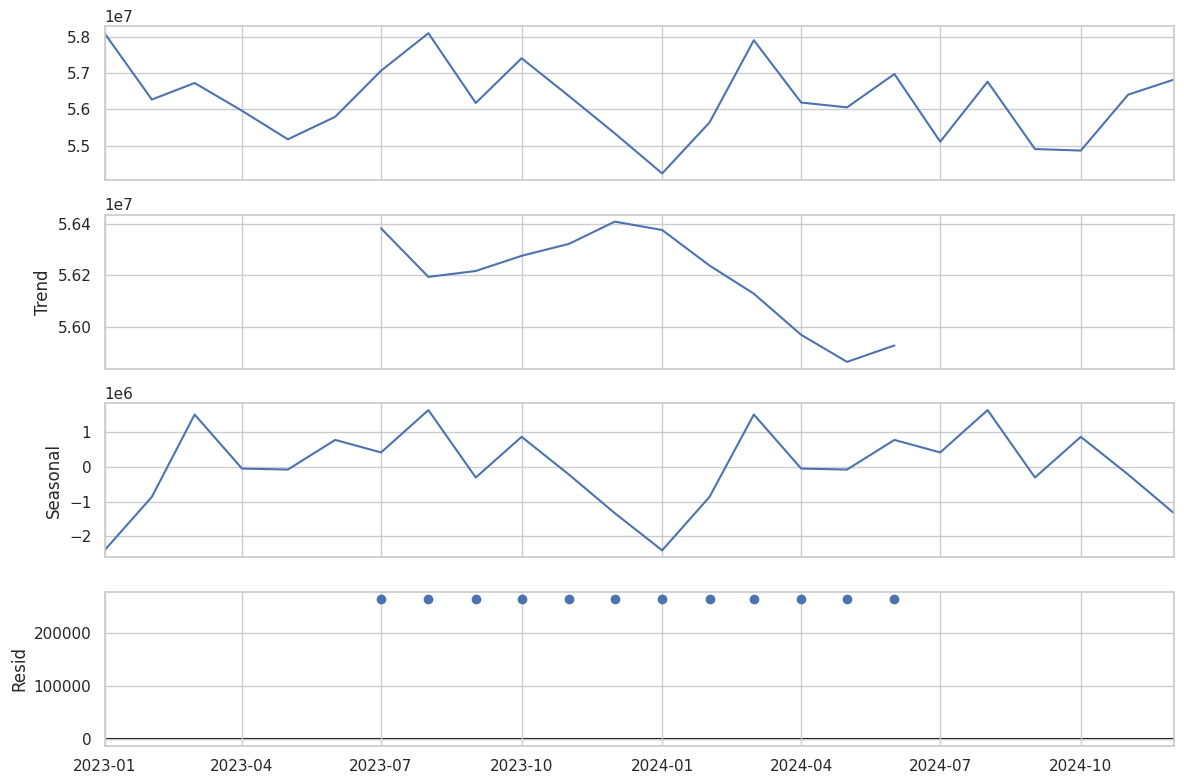

Trend moves only 1.0% of the average level between its highest and lowest point → essentially flat.
Correlation between the 2023 and 2024 monthly patterns: r = -0.36 (p = 0.25) → NO reliable repeating seasonality


In [27]:
decomp = seasonal_decompose(daily_avg, model="additive", period=12)
fig = decomp.plot(); fig.set_size_inches(12, 8); plt.tight_layout(); plt.show()

trend_range = decomp.trend.dropna().max() - decomp.trend.dropna().min()
print(f"Trend moves only {trend_range / daily_avg.mean():.1%} of the average level between its highest and lowest point → essentially flat.")

# IMPORTANT: with only 2 years of data, the 'Seasonal' panel above simply repeats the average of the two years,
# so it ALWAYS looks regular. The honest test is whether the 2023 pattern matches the 2024 pattern.
r_season, p_season = stats.pearsonr(daily_avg["2023"].values, daily_avg["2024"].values)
print(f"Correlation between the 2023 and 2024 monthly patterns: r = {r_season:.2f} (p = {p_season:.2f}) →",
      "seasonality repeats" if (r_season > 0.5 and p_season < 0.05) else "NO reliable repeating seasonality")

**TEST STATIONARITY AND TRENDS**

In [28]:
TEST_MONTHS = 6
train_daily = daily_avg.iloc[:-TEST_MONTHS]                 # models learn from the first 18 months
test        = monthly_rev.iloc[-TEST_MONTHS:]               # we judge them on the last 6 months of REAL revenue
test_days   = days_in_month.iloc[-TEST_MONTHS:].values
print(f"Training: {train_daily.index.min():%b %Y} → {train_daily.index.max():%b %Y} ({len(train_daily)} months)")
print(f"Testing : {test.index.min():%b %Y} → {test.index.max():%b %Y} ({len(test)} months)")

def fit_and_forecast(name, series, steps, arima_order=None):
    # Fits one model on `series` (revenue per day). Returns (forecast per day, typical error per day)
    if name == "Simple Exp. Smoothing":
        fit = ExponentialSmoothing(series, trend=None, initialization_method="estimated").fit()
    elif name == "Holt (damped trend)":
        fit = ExponentialSmoothing(series, trend="add", damped_trend=True, initialization_method="estimated").fit()
    else:   # ARIMA with a constant term (d = 0 because the ADF test says the series is stationary)
        fit = SARIMAX(series, order=arima_order, trend="c").fit(disp=False)
    return np.asarray(fit.forecast(steps)), fit.resid.iloc[1:].std()

# Pick the best ARIMA(p, 0, q) using AIC (lower = better). (0,0,0) is only the average, so we skip it.
best_aic, best_order = np.inf, None
for p in range(3):
    for q in range(3):
        if p + q == 0:
            continue
        try:
            res = SARIMAX(train_daily, order=(p, 0, q), trend="c").fit(disp=False)
            if res.aic < best_aic:
                best_aic, best_order = res.aic, (p, 0, q)
        except Exception:
            pass
arima_name = f"ARIMA{best_order}"
print("Best ARIMA order selected by AIC:", best_order)

test_forecasts = {}
# --- Baselines: simple rules that any real model should try to beat
test_forecasts["Naive (last month)"]          = np.repeat(train_daily.iloc[-1], TEST_MONTHS) * test_days
test_forecasts["Historical Average"]          = np.repeat(train_daily.mean(), TEST_MONTHS) * test_days
test_forecasts["Moving Average (3 months)"]   = np.repeat(train_daily.iloc[-3:].mean(), TEST_MONTHS) * test_days
test_forecasts["Seasonal Naive (same month last year)"] = train_daily.iloc[-12:-12 + TEST_MONTHS].values * test_days
baseline_names = list(test_forecasts.keys())
# --- Statistical models
for model_name in ["Simple Exp. Smoothing", "Holt (damped trend)", arima_name]:
    fc, _ = fit_and_forecast(model_name, train_daily, TEST_MONTHS, best_order)
    test_forecasts[model_name] = fc * test_days
test_forecasts = {k: pd.Series(np.asarray(v), index=test.index) for k, v in test_forecasts.items()}


Training: Jan 2023 → Jun 2024 (18 months)
Testing : Jul 2024 → Dec 2024 (6 months)
Best ARIMA order selected by AIC: (0, 0, 1)


**TEST STATIONARITY AND TRENDS**

,MAE (₹ Cr),RMSE (₹ Cr),MAPE (%),Type
Moving Average (3 months),2.62,3.23,1.55,Baseline
Holt (damped trend),2.64,3.00,1.55,Statistical model
Simple Exp. Smoothing,2.63,3.24,1.55,Statistical model
Historical Average,2.63,3.25,1.55,Baseline
"ARIMA(0, 0, 1)",2.74,3.22,1.61,Statistical model
Naive (last month),3.57,4.45,2.11,Baseline
Seasonal Naive (same month last year),4.45,5.05,2.60,Baseline



✔ Selected model: Holt (damped trend)   (test MAPE = 1.55%, i.e. average error about 1.6% per month)
  Best baseline: Moving Average (3 months) (1.55%).  Seasonal Naive scored 2.60% – copying last year's month does NOT help, which confirms there is no repeating seasonality.


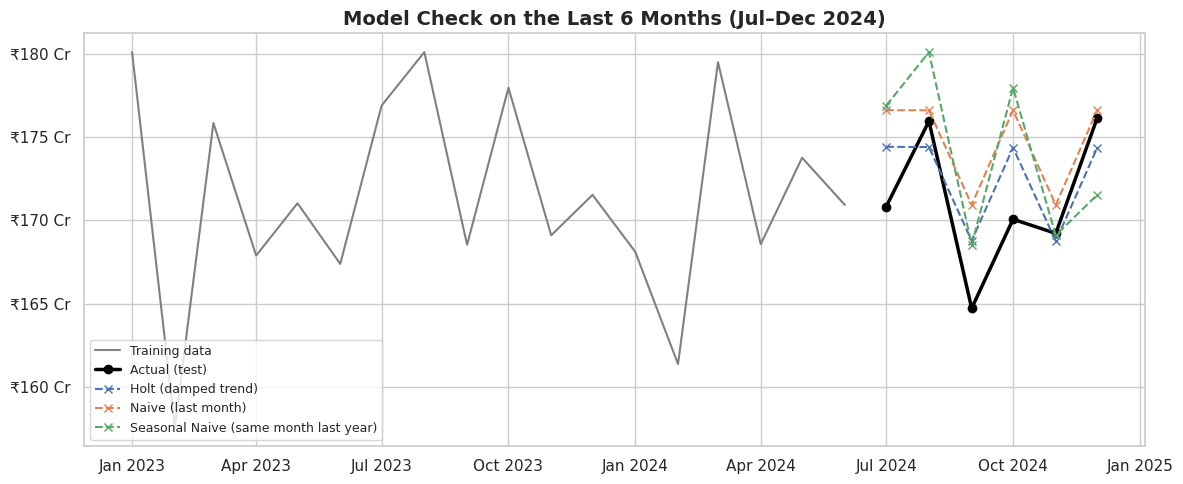

In [29]:
def evaluate(actual, predicted):
    err = actual.values - predicted.values
    return {"MAE (₹ Cr)": np.mean(np.abs(err)) / 1e7,
            "RMSE (₹ Cr)": np.sqrt(np.mean(err ** 2)) / 1e7,
            "MAPE (%)": np.mean(np.abs(err / actual.values)) * 100}

comparison = pd.DataFrame({k: evaluate(test, v) for k, v in test_forecasts.items()}).T
comparison["Type"] = ["Baseline" if k in baseline_names else "Statistical model" for k in comparison.index]
comparison = comparison.sort_values("MAPE (%)")
display(comparison)

# Choose the best STATISTICAL model (baselines are only benchmarks)
candidates = comparison[comparison["Type"] == "Statistical model"]
best_model = candidates.index[0]
best_baseline = comparison[comparison["Type"] == "Baseline"].iloc[0]
print(f"\n✔ Selected model: {best_model}   (test MAPE = {candidates.iloc[0]['MAPE (%)']:.2f}%, i.e. average error about {candidates.iloc[0]['MAPE (%)']:.1f}% per month)")
print(f"  Best baseline: {best_baseline.name} ({best_baseline['MAPE (%)']:.2f}%).  Seasonal Naive scored {comparison.loc['Seasonal Naive (same month last year)', 'MAPE (%)']:.2f}% – copying last year's month does NOT help, which confirms there is no repeating seasonality.")

plt.figure(figsize=(12, 5))
plt.plot(monthly_rev.index[:-TEST_MONTHS], monthly_rev.values[:-TEST_MONTHS], color="grey", label="Training data")
plt.plot(test.index, test.values, color="black", linewidth=2.5, marker="o", label="Actual (test)")
for k in [best_model, "Naive (last month)", "Seasonal Naive (same month last year)"]:
    plt.plot(test.index, test_forecasts[k].values, linestyle="--", marker="x", label=k)
plt.gca().yaxis.set_major_formatter(cr_axis)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.title("Model Check on the Last 6 Months (Jul–Dec 2024)"); plt.legend(fontsize=9, loc="lower left"); plt.tight_layout(); plt.show()

**DECOMPOSE REVENUE TIME SERIES**

Model used: Holt (damped trend)


,Forecast (₹ Cr),Lower 95% (₹ Cr),Upper 95% (₹ Cr)
Jan 2025,173.30,167.40,179.30
Feb 2025,156.50,151.10,161.90
Mar 2025,173.20,167.30,179.10
Apr 2025,167.50,161.80,173.30
May 2025,173.00,167.10,179.00
Jun 2025,167.40,161.60,173.10


Total forecast Jan–Jun 2025: ₹1,011 Cr   |   Same months in 2024: ₹1,022 Cr


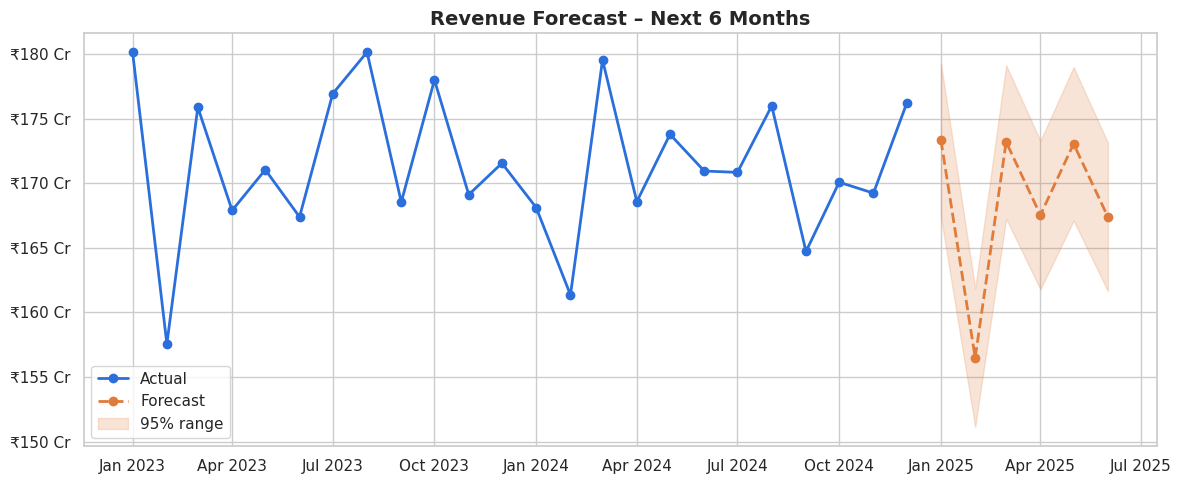

In [30]:
FORECAST_MONTHS = 6
future_index = pd.date_range(monthly_rev.index[-1] + pd.offsets.MonthBegin(1), periods=FORECAST_MONTHS, freq="MS")
future_days  = np.asarray(future_index.days_in_month)

fc_per_day, resid_std = fit_and_forecast(best_model, daily_avg, FORECAST_MONTHS, best_order)
forecast_df = pd.DataFrame({"Forecast": fc_per_day * future_days}, index=future_index)
forecast_df["Lower_95"] = forecast_df["Forecast"] - 1.96 * resid_std * future_days      # approximate 95% range
forecast_df["Upper_95"] = forecast_df["Forecast"] + 1.96 * resid_std * future_days

show = (forecast_df / 1e7).round(1)
show.index = show.index.strftime("%b %Y")
show.columns = ["Forecast (₹ Cr)", "Lower 95% (₹ Cr)", "Upper 95% (₹ Cr)"]
print(f"Model used: {best_model}")
display(show)
print(f"Total forecast Jan–Jun 2025: ₹{forecast_df['Forecast'].sum()/1e7:,.0f} Cr   |   Same months in 2024: ₹{monthly_rev['2024-01':'2024-06'].sum()/1e7:,.0f} Cr")

plt.figure(figsize=(12, 5))
plt.plot(monthly_rev.index, monthly_rev.values, marker="o", color="#2a6fdb", linewidth=2, label="Actual")
plt.plot(forecast_df.index, forecast_df["Forecast"], marker="o", color="#e07b39", linewidth=2, linestyle="--", label="Forecast")
plt.fill_between(forecast_df.index, forecast_df["Lower_95"], forecast_df["Upper_95"], color="#e07b39", alpha=0.2, label="95% range")
plt.gca().yaxis.set_major_formatter(cr_axis)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.title("Revenue Forecast – Next 6 Months"); plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

In [31]:
g = df.groupby("Store_Location")
yearly = df.pivot_table(index="Store_Location", columns="Year", values="Revenue", aggfunc="sum")

store_features = pd.DataFrame({
    "Store_ID":              g["Store_ID"].first(),
    "Region":                g["Region"].first(),
    "Total_Revenue_Cr":      g["Revenue"].sum() / 1e7,
    "Avg_Transaction_Value": g["Revenue"].mean(),
    "YoY_Growth_%":          (yearly[2024] / yearly[2023] - 1) * 100,
    "Avg_Rating":            g["Store_Rating"].mean(),
    "Avg_Units_Per_Sale":    g["Units_Sold"].mean(),
    "Avg_Discount_%":        g["Discount_Percentage"].mean(),
    "Promo_Rate_%":          g["Promotion_Applied"].apply(lambda s: (s == "Yes").mean() * 100),
    "Returning_Cust_%":      g["Customer_Type"].apply(lambda s: (s == "Returning").mean() * 100),
})
feature_cols = ["Total_Revenue_Cr", "Avg_Transaction_Value", "YoY_Growth_%", "Avg_Rating",
                "Avg_Units_Per_Sale", "Avg_Discount_%", "Promo_Rate_%", "Returning_Cust_%"]
display(store_features)

,Store_ID,Region,Total_Revenue_Cr,Avg_Transaction_Value,YoY_Growth_%,Avg_Rating,Avg_Units_Per_Sale,Avg_Discount_%,Promo_Rate_%,Returning_Cust_%
Store_Location,,,,,,,,,,
Ahmedabad,STR_108,West,507.83,"562,757.31",-0.25,4.25,24.82,9.94,29.86,59.36
Bangalore,STR_102,South,518.63,"565,323.37",3.66,4.25,24.89,10.00,30.09,59.12
Chennai,STR_104,South,516.59,"562,370.72",-2.11,4.25,24.88,10.11,29.59,60.82
Delhi,STR_103,North,522.31,"569,395.43",-2.34,4.25,25.02,9.97,29.51,59.34
Hyderabad,STR_106,South,504.08,"559,216.36",-1.54,4.25,24.75,9.94,30.11,60.05
Kolkata,STR_107,East,510.78,"559,088.47",0.88,4.25,25.11,9.95,30.23,60.61
Mumbai,STR_101,West,516.97,"571,930.00",-2.12,4.25,25.08,10.09,29.59,60.18
Pune,STR_105,West,516.19,"557,801.89",-1.77,4.25,24.61,10.08,30.45,60.31


**CREATING AND COMPARING FORECASTING MODELS**

In [32]:
X = StandardScaler().fit_transform(store_features[feature_cols])

scores = {}
for k in range(2, 5):                                   # with only 8 stores, 2–4 groups is sensible
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels)
    print(f"k = {k}  → silhouette score = {scores[k]:.3f}")

best_k = max(scores, key=scores.get)
print(f"\nBest k = {best_k}")
print("Note: scores below ~0.25 mean the groups are only weakly separated – the stores are quite similar to each other.")

k = 2  → silhouette score = 0.222
k = 3  → silhouette score = 0.215
k = 4  → silhouette score = 0.194

Best k = 2
Note: scores below ~0.25 mean the groups are only weakly separated – the stores are quite similar to each other.


**Interpret Store Segments Using K-Means Clustering**

In [33]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
store_features["Cluster"] = kmeans.fit_predict(X)

# Name each segment from what it really looks like: revenue level + growth direction
cluster_avg  = store_features.groupby("Cluster")[["Total_Revenue_Cr", "YoY_Growth_%"]].mean()
overall_rev  = store_features["Total_Revenue_Cr"].mean()
overall_gr   = store_features["YoY_Growth_%"].mean()
cluster_avg  = cluster_avg.sort_values("Total_Revenue_Cr", ascending=False)

segment_name = {}
for cl, row in cluster_avg.iterrows():
    rev_label = "Higher-Revenue" if row["Total_Revenue_Cr"] >= overall_rev else "Lower-Revenue"
    gr_label  = "Growing" if row["YoY_Growth_%"] >= overall_gr else "Declining"
    segment_name[cl] = f"{rev_label} / {gr_label}"
# if two clusters got the same name, add a number so they stay distinguishable
names = list(segment_name.values())
for cl in segment_name:
    if names.count(segment_name[cl]) > 1:
        segment_name[cl] += f" (Group {cl + 1})"

store_features["Segment"] = store_features["Cluster"].map(segment_name)
segment_order = [segment_name[cl] for cl in cluster_avg.index]       # highest revenue first

print("Stores in each segment:")
for seg_name in segment_order:
    members = store_features.index[store_features["Segment"] == seg_name].tolist()
    print(f"  {seg_name:<32}: {', '.join(members)}")

print("\nSegment profile (average of each feature):")
profile = store_features.groupby("Segment")[feature_cols].mean().loc[segment_order]
display(profile)

Stores in each segment:
  Higher-Revenue / Declining      : Chennai, Delhi, Mumbai
  Lower-Revenue / Growing         : Ahmedabad, Bangalore, Hyderabad, Kolkata, Pune

Segment profile (average of each feature):


,Total_Revenue_Cr,Avg_Transaction_Value,YoY_Growth_%,Avg_Rating,Avg_Units_Per_Sale,Avg_Discount_%,Promo_Rate_%,Returning_Cust_%
Segment,,,,,,,,
Higher-Revenue / Declining,518.62,"567,898.72",-2.19,4.25,24.99,10.06,29.56,60.11
Lower-Revenue / Growing,511.50,"560,837.48",0.19,4.25,24.84,9.98,30.15,59.89


**Visualize Store Segmentation Using PCA**

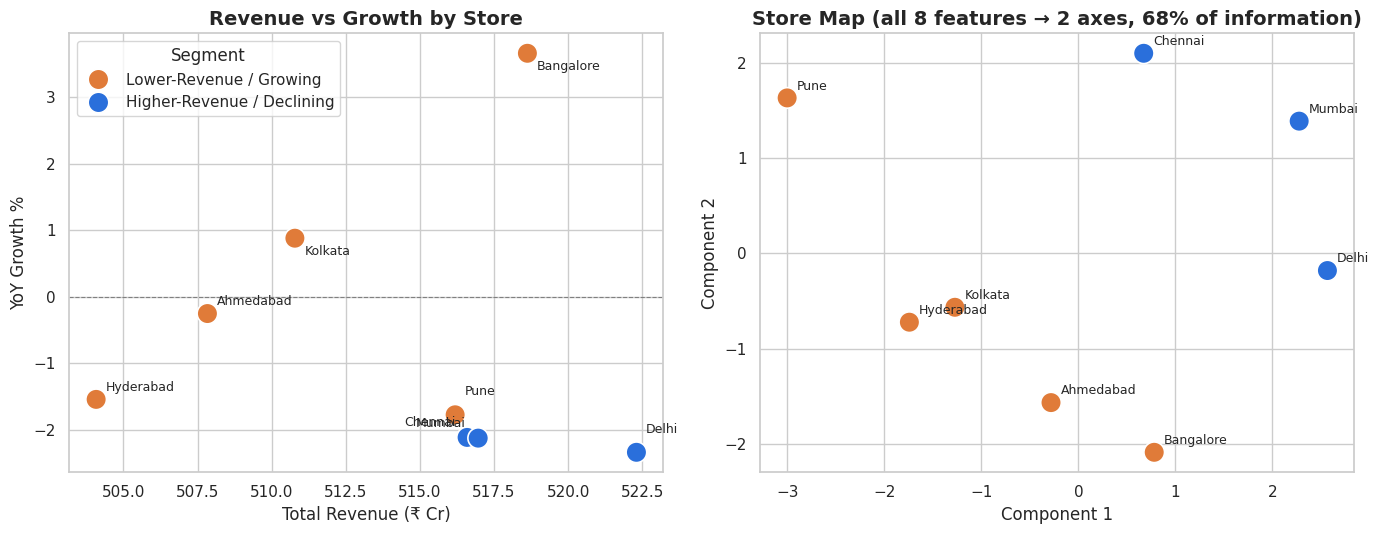

In [34]:
palette = dict(zip(segment_order, ["#2a6fdb", "#e07b39", "#2e9e5b", "#9b59b6"][:best_k]))
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
store_features["PC1"], store_features["PC2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
# Left: revenue vs growth
sns.scatterplot(data=store_features, x="Total_Revenue_Cr", y="YoY_Growth_%", hue="Segment", palette=palette, s=220, ax=axes[0])
offsets = [(7, 6), (7, -12), (-45, 8), (7, 14)]                      # stops labels overlapping
for i, (city, row) in enumerate(store_features.iterrows()):
    axes[0].annotate(city, (row["Total_Revenue_Cr"], row["YoY_Growth_%"]), xytext=offsets[i % 4], textcoords="offset points", fontsize=9)
axes[0].axhline(0, color="grey", linewidth=0.8, linestyle="--")
axes[0].set_title("Revenue vs Growth by Store"); axes[0].set_xlabel("Total Revenue (₹ Cr)"); axes[0].set_ylabel("YoY Growth %")
# Right: PCA map of all 8 features
sns.scatterplot(data=store_features, x="PC1", y="PC2", hue="Segment", palette=palette, s=220, ax=axes[1], legend=False)
for city, row in store_features.iterrows():
    axes[1].annotate(city, (row["PC1"], row["PC2"]), xytext=(7, 6), textcoords="offset points", fontsize=9)
axes[1].set_title(f"Store Map (all 8 features → 2 axes, {pca.explained_variance_ratio_.sum():.0%} of information)")
axes[1].set_xlabel("Component 1"); axes[1].set_ylabel("Component 2")
plt.tight_layout(); plt.show()

**RECOMMENDATIONS FOR BUSINESS**

In [35]:
# ================================================================
# EXECUTIVE BUSINESS RECOMMENDATIONS
# Data-driven actions based on existing project results
# ================================================================

print("=" * 85)
print("EXECUTIVE DECISION BRIEF: RETAIL BUSINESS")
print("=" * 85)

# 1. Revenue growth and business performance
yoy_growth = (rev_2024 / rev_2023 - 1) * 100

print("\n1. REVENUE GROWTH AND PERFORMANCE")
print("-" * 85)

if yoy_growth < 0:
    print(f"Finding: Revenue declined by {abs(yoy_growth):.2f}% in 2024.")
    print("Recommendation: Introduce a store-level recovery plan.")
    print("Actions:")
    print("- Investigate declining stores, product mix, transaction values and margins.")
    print("- Set monthly revenue recovery targets for underperforming stores.")
    print("- Review progress against the same period in the previous year.")
else:
    print(f"Finding: Revenue grew by {yoy_growth:.2f}% in 2024.")
    print("Recommendation: Identify the strongest growth drivers and replicate")
    print("successful practices across comparable stores.")

print("KPIs: Year-over-year revenue growth, revenue per transaction, gross margin.")

# 2. Store-level intervention
print("\n2. STORE PERFORMANCE AND RESOURCE ALLOCATION")
print("-" * 85)

weak_store = store.sort_values("YoY_Growth_%").iloc[0]
strong_store = store.sort_values("YoY_Growth_%").iloc[-1]

print(
    f"Finding: {strong_store['Store_Location']} recorded the strongest "
    f"store growth ({strong_store['YoY_Growth_%']:+.2f}%)."
)
print(
    f"Finding: {weak_store['Store_Location']} recorded the weakest "
    f"store growth ({weak_store['YoY_Growth_%']:+.2f}%)."
)

print("Recommendation:")
print("- Investigate the weakest store to identify correctable performance gaps.")
print("- Study the strongest store's sales mix and customer-retention practices.")
print("- Allocate additional resources only after validating the underlying causes.")
print("KPIs: Store revenue growth, average transaction value, units per transaction.")

# 3. ML-based store segmentation
print("\n3. MACHINE-LEARNING STORE SEGMENTATION")
print("-" * 85)

if "Segment" in store_features.columns:
    segment_summary = (
        store_features.groupby("Segment")
        .agg(
            Stores=("Store_ID", "count"),
            Avg_Revenue_Cr=("Total_Revenue_Cr", "mean"),
            Avg_Growth_Pct=("YoY_Growth_%", "mean"),
            Avg_Rating=("Avg_Rating", "mean")
        )
        .sort_values("Avg_Growth_Pct", ascending=False)
    )

    display(segment_summary.round(2))

    for segment, row in segment_summary.iterrows():
        print(f"\nSegment: {segment}")
        print(f"Stores: {int(row['Stores'])}")
        print(f"Average store revenue: ₹{row['Avg_Revenue_Cr']:.2f} crore")
        print(f"Average YoY growth: {row['Avg_Growth_Pct']:+.2f}%")

        if row["Avg_Growth_Pct"] < 0:
            print("Action: Diagnose declining performance and prepare a targeted")
            print("recovery plan for stores in this segment.")
        else:
            print("Action: Validate successful practices and evaluate opportunities")
            print("to scale them across comparable stores.")

    print("\nImportant: Clusters identify similar stores, not proven causes.")
    print("Validate proposed actions before committing significant resources.")
else:
    print("Store segments are not available. Run the K-Means cells first.")

print("KPIs: Segment-level growth, revenue, customer retention and store rating.")

# 4. Discount and promotion effectiveness
print("\n4. DISCOUNT AND PROMOTION OPTIMIZATION")
print("-" * 85)

discount_data = disc.sort_index()

if len(discount_data) >= 2:
    low_discount = discount_data.iloc[0]
    high_discount = discount_data.iloc[-1]

    print(
        f"Average revenue per transaction at the lowest discount: "
        f"₹{low_discount['Avg_Revenue']:,.2f}"
    )
    print(
        f"Average revenue per transaction at the highest discount: "
        f"₹{high_discount['Avg_Revenue']:,.2f}"
    )
    print(
        f"Average units per transaction: "
        f"{low_discount['Avg_Units']:.2f} vs "
        f"{high_discount['Avg_Units']:.2f}"
    )

    print("\nRecommendation:")
    print("Finding: Higher discount levels are associated with lower")
    print("average revenue per transaction in this dataset.")
    print("Limitation: This comparison does not establish causation.")
    print("Recommendation: Run controlled promotion experiments before")
    print("expanding discounts across stores.")

    print("- Compare incremental sales, gross margin and customer response.")
    print("- Run controlled tests before expanding a promotion.")
    print("KPIs: Gross margin, incremental revenue, units sold and promotion ROI.")

# 5. Forecasting and planning
print("\n5. FORECAST-LED BUSINESS PLANNING")
print("-" * 85)

if "Forecast" in forecast_df.columns:
    forecast_total = forecast_df["Forecast"].sum()
    print(f"Forecast model: {best_model}")
    print(
        f"Forecast horizon: {forecast_df.index.min():%b %Y} "
        f"to {forecast_df.index.max():%b %Y}"
    )
    print(f"Forecast total: ₹{forecast_total / 1e7:,.2f} crore")

    print("\nRecommendation:")
    print("- Use forecasts as planning inputs for inventory, staffing and purchasing.")
    print("- Monitor forecast error as new actual sales become available.")
    print("- Refit and validate the model using newer data before using it operationally.")
    print("KPIs: Forecast MAPE, stockout rate, inventory turnover and forecast bias.")

print("\nDATA LIMITATION")
print("- The supplied dataset covers January 2023 to December 2024.")
print("- The existing forecast therefore concerns January to June 2025.")
print("- It is a historical forecast, not a current forecast for 2026.")
print("- Update the dataset and rerun model validation before making current plans.")

print("\n" + "=" * 85)
print("END OF EXECUTIVE DECISION BRIEF")
print("=" * 85)

EXECUTIVE DECISION BRIEF: RETAIL BUSINESS

1. REVENUE GROWTH AND PERFORMANCE
-------------------------------------------------------------------------------------
Finding: Revenue declined by 0.72% in 2024.
Recommendation: Introduce a store-level recovery plan.
Actions:
- Investigate declining stores, product mix, transaction values and margins.
- Set monthly revenue recovery targets for underperforming stores.
- Review progress against the same period in the previous year.
KPIs: Year-over-year revenue growth, revenue per transaction, gross margin.

2. STORE PERFORMANCE AND RESOURCE ALLOCATION
-------------------------------------------------------------------------------------
Finding: Bangalore recorded the strongest store growth (+3.66%).
Finding: Delhi recorded the weakest store growth (-2.34%).
Recommendation:
- Investigate the weakest store to identify correctable performance gaps.
- Study the strongest store's sales mix and customer-retention practices.
- Allocate additional res

,Stores,Avg_Revenue_Cr,Avg_Growth_Pct,Avg_Rating
Segment,,,,
Lower-Revenue / Growing,5,511.50,0.19,4.25
Higher-Revenue / Declining,3,518.62,-2.19,4.25



Segment: Lower-Revenue / Growing
Stores: 5
Average store revenue: ₹511.50 crore
Average YoY growth: +0.19%
Action: Validate successful practices and evaluate opportunities
to scale them across comparable stores.

Segment: Higher-Revenue / Declining
Stores: 3
Average store revenue: ₹518.62 crore
Average YoY growth: -2.19%
Action: Diagnose declining performance and prepare a targeted
recovery plan for stores in this segment.

Important: Clusters identify similar stores, not proven causes.
Validate proposed actions before committing significant resources.
KPIs: Segment-level growth, revenue, customer retention and store rating.

4. DISCOUNT AND PROMOTION OPTIMIZATION
-------------------------------------------------------------------------------------
Average revenue per transaction at the lowest discount: ₹627,932.46
Average revenue per transaction at the highest discount: ₹498,737.41
Average units per transaction: 24.91 vs 24.80

Recommendation:
Finding: Higher discount levels are asso

**Build Store Level Feature Dataset for Clustering**

In [36]:
# 1) Clean transaction data (all 73,000 rows + new columns)
df.to_csv("retail_cleaned_for_powerbi.csv", index=False)

# 2) Monthly actual + forecast (one continuous table for the forecast page)
actual_part = pd.DataFrame({"Month": monthly_rev.index, "Actual": monthly_rev.values})
future_part = forecast_df.reset_index().rename(columns={"index": "Month"})
forecast_export = pd.concat([actual_part, future_part], ignore_index=True)
forecast_export["Type"] = np.where(forecast_export["Actual"].notna(), "Actual", "Forecast")
forecast_export["Model"] = best_model
forecast_export.to_csv("monthly_forecast.csv", index=False)

# 3) Store segments
store_features.reset_index().drop(columns=["Cluster", "PC1", "PC2"]).to_csv("store_segments.csv", index=False)

# 4) Model comparison table (for the report)
comparison.reset_index().rename(columns={"index": "Model"}).to_csv("model_comparison.csv", index=False)

print("Files created:")
for f in ["retail_cleaned_for_powerbi.csv", "monthly_forecast.csv", "store_segments.csv", "model_comparison.csv"]:
    print("  •", f)

Files created:
  • retail_cleaned_for_powerbi.csv
  • monthly_forecast.csv
  • store_segments.csv
  • model_comparison.csv


**Final Business Findings**

In [37]:
top_store   = store.iloc[0];  low_store = store.iloc[-1]
grow_store  = store.sort_values("YoY_Growth_%").iloc[-1]; fall_store = store.sort_values("YoY_Growth_%").iloc[0]
top_cat     = cat.iloc[0];    low_cat   = cat.iloc[-1]
top_region  = region.sort_values("Revenue", ascending=False).iloc[0]
yoy_total   = (rev_2024 / rev_2023 - 1) * 100

print("=" * 70)
print("KEY FINDINGS")
print("=" * 70)
print(f"1. Total revenue (2023–24): ₹{total_revenue/1e7:,.0f} Cr. 2023 = ₹{rev_2023/1e7:,.0f} Cr, 2024 = ₹{rev_2024/1e7:,.0f} Cr ({yoy_total:+.2f}% YoY).")
print(f"2. Top store: {top_store['Store_Location']} (₹{top_store['Revenue_Cr']:,.0f} Cr); lowest: {low_store['Store_Location']} (₹{low_store['Revenue_Cr']:,.0f} Cr). Gap between best and worst store is only {(top_store['Revenue']/low_store['Revenue']-1)*100:.1f}%.")
print(f"3. Fastest-growing store in 2024: {grow_store['Store_Location']} ({grow_store['YoY_Growth_%']:+.1f}%); weakest: {fall_store['Store_Location']} ({fall_store['YoY_Growth_%']:+.1f}%).")
print(f"4. Top category: {top_cat['Product_Category']} ({top_cat['Share_%']:.1f}% share); lowest: {low_cat['Product_Category']} ({low_cat['Share_%']:.1f}%). All five categories are within a very narrow band.")
print(f"5. Top region: {top_region['Region']} ({top_region['Share_%']:.1f}% of revenue; it has {top_region['Stores']} stores).")
print(f"6. Seasonality: strongest month {seasonal_idx.idxmax()} ({seasonal_idx.max():.0f}), weakest {seasonal_idx.idxmin()} ({seasonal_idx.min():.0f}) – a spread of only {seasonal_idx.max()-seasonal_idx.min():.0f} index points; the 2023 and 2024 monthly patterns correlate at r = {r:.2f}, so seasonality is not reliable.")
print(f"7. Revenue is driven mainly by Unit_Price (r = {corr.loc['Unit_Price','Revenue']:.2f}) and Units_Sold (r = {corr.loc['Units_Sold','Revenue']:.2f}).")
print(f"8. Discounts reduce revenue per sale ({disc['Avg_Revenue'].iloc[0]/1e5:.2f} lakh at 0% vs {disc['Avg_Revenue'].iloc[-1]/1e5:.2f} lakh at 20%) without raising units sold ({disc['Avg_Units'].iloc[0]:.1f} vs {disc['Avg_Units'].iloc[-1]:.1f}).")
print(f"9. Forecast: ₹{forecast_df['Forecast'].sum()/1e7:,.0f} Cr for Jan–Jun 2025 using {best_model} (test MAPE {candidates.iloc[0]['MAPE (%)']:.2f}%).")
print(f"10. Store segmentation: {best_k} segments (silhouette = {scores[best_k]:.2f}, weak separation):")
for seg_name in segment_order:
    print(f"      • {seg_name}: {', '.join(store_features.index[store_features['Segment'] == seg_name])}")

KEY FINDINGS
1. Total revenue (2023–24): ₹4,113 Cr. 2023 = ₹2,064 Cr, 2024 = ₹2,049 Cr (-0.72% YoY).
2. Top store: Delhi (₹522 Cr); lowest: Hyderabad (₹504 Cr). Gap between best and worst store is only 3.6%.
3. Fastest-growing store in 2024: Bangalore (+3.7%); weakest: Delhi (-2.3%).
4. Top category: Electronics (20.2% share); lowest: Sports (19.9%). All five categories are within a very narrow band.
5. Top region: West (37.5% of revenue; it has 3 stores).
6. Seasonality: strongest month Aug (102), weakest Sep (99) – a spread of only 3 index points; the 2023 and 2024 monthly patterns correlate at r = -0.36, so seasonality is not reliable.
7. Revenue is driven mainly by Unit_Price (r = 0.66) and Units_Sold (r = 0.65).
8. Discounts reduce revenue per sale (6.28 lakh at 0% vs 4.99 lakh at 20%) without raising units sold (24.9 vs 24.8).
9. Forecast: ₹1,011 Cr for Jan–Jun 2025 using Holt (damped trend) (test MAPE 1.55%).
10. Store segmentation: 2 segments (silhouette = 0.22, weak separation

# **FINAL REPORT**



```
==============================================================================
                 RETAIL ANALYTICS PROJECT REPORT
          AI-POWERED SALES FORECASTING & STORE SEGMENTATION
                 73,000 TRANSACTIONS | 2023–2024
==============================================================================

==============================================================================
 EXECUTIVE SUMMARY
==============================================================================
Total Revenue              : ₹ 4,113.38 Cr
Gross Sales Before Discount: ₹ 4,570.81 Cr
Total Discount Given       : ₹ 457.43 Cr
Total Units Sold           : 1,817,305
Transactions               : 73,000
Average Revenue/Record     : ₹ 563,476.00
Average Discount           : 10.01%
Average Store Rating       : 4.25 / 5
Returning Customers        : 59.98%
Stores                     : 8
Product Categories         : 5
Date Range                 : 01-Jan-2023 to 31-Dec-2024


==============================================================================
 YEARLY PERFORMANCE
==============================================================================
2023 Revenue               : ₹ 2,064.11 Cr
2024 Revenue               : ₹ 2,049.27 Cr
YoY Change                 : -0.72%

Interpretation             : Revenue remained broadly stable,
                             with a slight decline in 2024.


==============================================================================
 STORE PERFORMANCE
==============================================================================
STORE                 REVENUE       SHARE         YOY
-------------------------------------------------------
Delhi            ₹ 522.31 Cr     12.70%      -2.34%
Bangalore        ₹ 518.63 Cr     12.61%       3.66%
Mumbai           ₹ 516.97 Cr     12.57%      -2.12%
Chennai          ₹ 516.59 Cr     12.56%      -2.11%
Pune             ₹ 516.19 Cr     12.55%      -1.77%
Kolkata          ₹ 510.78 Cr     12.42%       0.88%
Ahmedabad        ₹ 507.83 Cr     12.35%      -0.25%
Hyderabad        ₹ 504.08 Cr     12.25%      -1.54%

Top Revenue Store           : Delhi
Fastest Growing Store       : Bangalore (+3.66%)
Weakest YoY Store           : Delhi (-2.34%)
Highest–Lowest Store Gap    : Approximately 3.6%


==============================================================================
 REGIONAL PERFORMANCE
==============================================================================
REGION                 REVENUE       SHARE       STORES
---------------------------------------------------------
West              ₹ 1,540.99 Cr     37.46%          3
South             ₹ 1,539.30 Cr     37.42%          3
North               ₹ 522.31 Cr     12.70%          1
East                ₹ 510.78 Cr     12.42%          1

Top Region                  : West
West + South Revenue Share  : 74.88%


==============================================================================
 PRODUCT CATEGORY PERFORMANCE
==============================================================================
CATEGORY                 REVENUE       SHARE          UNITS
-----------------------------------------------------------------
Electronics          ₹ 831.85 Cr     20.22%        367,921
Home Appliances      ₹ 826.28 Cr     20.09%        365,113
Fashion              ₹ 821.56 Cr     19.97%        361,431
Groceries            ₹ 817.05 Cr     19.86%        359,711
Sports               ₹ 816.63 Cr     19.85%        363,129

Top Category               : Electronics (20.22%)
Lowest Category            : Sports (19.85%)
Key Observation            : All five categories are highly balanced.


==============================================================================
 TOP REVENUE BRANDS
==============================================================================
 1. Levis                 ₹ 213.63 Cr
 2. Amul                  ₹ 210.83 Cr
 3. OnePlus               ₹ 209.16 Cr
 4. Samsung               ₹ 208.61 Cr
 5. LG                    ₹ 208.46 Cr
 6. Sony                  ₹ 208.17 Cr
 7. Philips               ₹ 208.01 Cr
 8. Prestige              ₹ 206.26 Cr
 9. Apple                 ₹ 205.92 Cr
10. Adidas                ₹ 205.88 Cr


==============================================================================
 CUSTOMER, DISCOUNT & PROMOTION ANALYSIS
==============================================================================
Returning Customer Share    : 59.98%
New Customer Share          : 40.02%

0% Discount Avg Revenue     : ₹ 627,932
20% Discount Avg Revenue    : ₹ 498,737
0% Discount Avg Units       : 24.91
20% Discount Avg Units      : 24.80

Promotion = YES Avg Revenue : ₹ 562,329
Promotion = NO Avg Revenue  : ₹ 563,967
Promotion Test p-value      : 0.8657

Key Observation             : Higher discounts reduced revenue per
                              transaction without materially increasing
                              units sold.


==============================================================================
 STATISTICAL TESTING
==============================================================================
Store ANOVA p-value         : 0.4530
Region ANOVA p-value        : 0.5253
Category ANOVA p-value      : 0.2080
Subcategory ANOVA p-value   : 0.4696
Brand ANOVA p-value         : 0.4281
Holiday t-test p-value      : 0.3970

Significance Level          : α = 0.05

Conclusion                  : No statistically significant difference
                              was detected in average revenue per
                              transaction across these groups.


==============================================================================
 REVENUE DRIVERS
==============================================================================
Unit Price vs Revenue       : r = 0.66
Units Sold vs Revenue       : r = 0.65
Discount vs Revenue         : r = -0.09
Holiday Flag vs Revenue     : r ≈ 0.00
Store Rating vs Revenue     : r ≈ 0.00
Stock vs Revenue            : r ≈ 0.00

Main Insight                : Revenue is most strongly associated
                              with Unit Price and Units Sold.

Note                        : Correlation does not prove causation.


==============================================================================
 SEASONAL & TIME PATTERN ANALYSIS
==============================================================================
Strongest Month             : August
Weakest Month               : September
Seasonal Index Spread       : 3.4 points
2023 vs 2024 Month Corr.    : r = -0.36
Correlation p-value         : 0.25
Month ANOVA p-value         : 0.96
Weekday ANOVA p-value       : 0.44

Conclusion                  : No reliable repeating seasonality
                              or strong weekday effect was detected.


==============================================================================
 AI / TIME-SERIES FORECASTING
==============================================================================
Training Period             : Jan-2023 to Jun-2024
Testing Period              : Jul-2024 to Dec-2024
Best Selected Model         : Holt Damped Trend
Validation MAPE             : 1.55%

FORECAST — JANUARY TO JUNE 2025
---------------------------------------------------------
MONTH          FORECAST          LOWER          UPPER
---------------------------------------------------------
January       ₹ 173.30 Cr      ₹ 167.40 Cr     ₹ 179.30 Cr
February      ₹ 156.50 Cr      ₹ 151.10 Cr     ₹ 161.90 Cr
March         ₹ 173.20 Cr      ₹ 167.30 Cr     ₹ 179.10 Cr
April         ₹ 167.50 Cr      ₹ 161.80 Cr     ₹ 173.30 Cr
May           ₹ 173.00 Cr      ₹ 167.10 Cr     ₹ 179.00 Cr
June          ₹ 167.40 Cr      ₹ 161.60 Cr     ₹ 173.10 Cr

6-Month Forecast Total      : ₹ 1,011 Cr
Same Period 2024 Revenue    : ₹ 1,022 Cr


==============================================================================
 STORE SEGMENTATION — K-MEANS
==============================================================================
K = 2 Silhouette Score       : 0.222
K = 3 Silhouette Score       : 0.215
K = 4 Silhouette Score       : 0.194
Selected K                  : 2

SEGMENT 1                   : HIGHER-REVENUE / DECLINING
Stores                      : Chennai, Delhi, Mumbai
Average Revenue             : ₹ 518.62 Cr
Average YoY Growth          : -2.19%

SEGMENT 2                   : LOWER-REVENUE / GROWING
Stores                      : Ahmedabad, Bangalore,
                              Hyderabad, Kolkata, Pune
Average Revenue             : ₹ 511.50 Cr
Average YoY Growth          : +0.19%

Segmentation Interpretation : Cluster separation is weak,
                              so segments should be used as
                              directional management groups.


==============================================================================
 KEY BUSINESS INSIGHTS
==============================================================================
1. Total revenue generated across 2023–2024 was ₹4,113 Cr.
2. Revenue declined slightly by 0.72% in 2024.
3. Delhi generated the highest total revenue at ₹522.31 Cr.
4. Bangalore was the fastest-growing store at +3.66%.
5. West and South together contributed approximately 74.88%
   of total revenue.
6. Product categories were highly balanced, with each contributing
   approximately 20% of total revenue.
7. Higher discounts reduced revenue per transaction but did not
   materially increase units sold.
8. Unit Price and Units Sold were the strongest revenue-associated
   variables.
9. No statistically significant seasonal or holiday effect was found.
10. Holt Damped Trend achieved a 1.55% validation MAPE.
11. The Jan–Jun 2025 forecast is approximately ₹1,011 Cr.
12. Store segmentation produced two weakly separated groups.


==============================================================================
 PROJECT DELIVERABLES
==============================================================================
[✓] Data Cleaning & Validation
[✓] Business Rule Validation
[✓] KPI Analysis
[✓] Store Performance Analysis
[✓] Regional Analysis
[✓] Product Category Analysis
[✓] Brand Analysis
[✓] Discount & Promotion Analysis
[✓] Customer Analysis
[✓] Statistical Testing
[✓] Correlation Analysis
[✓] Seasonality Analysis
[✓] Time-Series Forecasting
[✓] Store Segmentation using K-Means
[✓] PCA Visualization
[✓] CSV Outputs


==============================================================================
 FINAL CONCLUSION
==============================================================================
The retail business shows a stable but nearly flat revenue pattern
across 2023–2024. Performance is broadly balanced across stores and
product categories, while Unit Price and Units Sold are the strongest
revenue-associated factors. Discount-heavy transactions generate
lower revenue without a meaningful increase in units sold.

Forecasting indicates approximately ₹1,011 Cr revenue for Jan–Jun
2025, with a validation MAPE of 1.55%. Store segmentation identifies
higher-revenue declining stores and lower-revenue growing stores,
providing a useful basis for targeted management action.


==============================================================================
                  END OF FINAL PROJECT REPORT
==============================================================================

```

